# Backgammon AI: Expectiminimax and Monte Carlo opponents

**Name:** Krishna Mahajan
**Student ID:** 106wucww
**Module:** 5FTC2067 Artificial Intelligence Principles, Mini Project
University of Hertfordshire (delivered at PSB Academy, Singapore)

This notebook contains **all of the code** for the project and **runs the AI live**:

1. The source files (each cell writes one file, so running the notebook rebuilds the game).
2. Demonstrations: the rules, the evaluation function, one Expectiminimax decision traced
   step by step, Monte Carlo rollouts, the win probability and doubling cube, a small live
   tournament and the automated tests.
3. The last cell **launches the published game** (a desktop window).

**To run:** `pip install pygame-ce matplotlib`, then *Run All*. Every function in the code has
a comment describing what it does and its parameters.

In [1]:
# Check the two libraries the project needs
import importlib.util
for lib in ("pygame", "matplotlib"):
    print(f"{lib:11s}", "installed" if importlib.util.find_spec(lib) else "MISSING - run: pip install pygame-ce matplotlib")

pygame      installed
matplotlib  installed


## Part 1: The source code

### Step 1 - Rules engine: `backgammon.py`

The board, the dice and every rule of backgammon: legal-turn generation (including the must-use-both-dice and larger-die rules), hitting, the bar and bearing off.

In [2]:
%%writefile backgammon.py
"""
Backgammon with Expectiminimax AI - Core Game Logic (Step 1)
Name:       Krishna Mahajan
Student ID: 106wucww
Module:     5FTC2067 Artificial Intelligence Principles - Mini Project

Board layout (indexes 0-23, shown to players as points 1-24):
  - Positive numbers = White checkers, negative numbers = Black checkers.
  - White moves from point 24 down to point 1; White's home board is points 1-6.
  - Black moves from point 1 up to point 24; Black's home board is points 19-24.
"""

import random

WHITE = 1
BLACK = -1
NUM_POINTS = 24
CHECKERS_PER_PLAYER = 15
PLAYER_NAMES = {WHITE: "White", BLACK: "Black"}


class GameState:
    """
    Stores one complete backgammon position.
    points : list of 24 ints (+ = White checkers, - = Black checkers)
    bar    : dict player -> number of that player's checkers on the bar
    off    : dict player -> number of that player's checkers borne off
    """

    def __init__(self, points=None, bar=None, off=None):
        """
        Creates a position (the standard start position if no points are given).
        Parameters:
          points: list of 24 ints (+White / -Black), or None for the start position
          bar: dict player -> checkers on the bar (None = empty)
          off: dict player -> checkers borne off (None = none)
        """
        # If no position is given, create the standard starting position
        if points is None:
            points = [0] * NUM_POINTS
            points[23], points[12], points[7], points[5] = 2, 5, 3, 5       # White
            points[0], points[11], points[16], points[18] = -2, -5, -3, -5  # Black
        self.points = points
        self.bar = bar if bar is not None else {WHITE: 0, BLACK: 0}
        self.off = off if off is not None else {WHITE: 0, BLACK: 0}

    def copy(self):
        """Returns an independent copy of this state (so the AI can explore safely)."""
        return GameState(self.points[:], dict(self.bar), dict(self.off))

    def key(self):
        """Returns a hashable summary of the state, used to remove duplicate positions."""
        return (tuple(self.points), self.bar[WHITE], self.bar[BLACK],
                self.off[WHITE], self.off[BLACK])

    def count_on(self, idx, player):
        """Returns how many of 'player's checkers are on point index 'idx'."""
        n = self.points[idx] * player
        return n if n > 0 else 0

    def is_open(self, idx, player):
        """True if 'player' may land on 'idx' (the opponent has fewer than 2 checkers there)."""
        return self.points[idx] * -player < 2

    def all_home(self, player):
        """True if every checker of 'player' still in play is in their home board."""
        if self.bar[player] > 0:
            return False
        outside = range(6, 24) if player == WHITE else range(0, 18)
        return all(self.count_on(i, player) == 0 for i in outside)

    def has_checkers_further(self, src, player):
        """
        True if 'player' has checkers in the home board further from bearing off than 'src'.
        Used for the rule that a higher die may bear off only from the furthest checker.
        """
        further = range(src + 1, 6) if player == WHITE else range(18, src)
        return any(self.count_on(i, player) > 0 for i in further)

    def winner(self):
        """Returns WHITE or BLACK if that player has borne off all 15 checkers, else None."""
        for p in (WHITE, BLACK):
            if self.off[p] == CHECKERS_PER_PLAYER:
                return p
        return None


def roll_dice():
    """Rolls two dice. Returns 4 copies of the value on a double (doubles are played 4 times)."""
    d1, d2 = random.randint(1, 6), random.randint(1, 6)
    return [d1] * 4 if d1 == d2 else [d1, d2]


def get_single_moves(state, player, die):
    """
    Returns every legal single-checker move for 'player' using one 'die' value.
    Each move is a tuple (src, dest): src is an index or 'bar', dest is an index or 'off'.
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      die: a single die value (1-6)
    """
    moves = []

    # Rule: a player with checkers on the bar must enter them before anything else
    if state.bar[player] > 0:
        dest = 24 - die if player == WHITE else die - 1
        if state.is_open(dest, player):
            moves.append(("bar", dest))
        return moves

    home_ready = state.all_home(player)
    direction = -1 if player == WHITE else 1

    # Both colours list their moves from their back checkers forwards. The AIs keep the first
    # of several equally scored turns, so scanning in the same order for both colours keeps
    # ties from favouring one colour (scanning 1-24 for both made Black stronger).
    order = range(NUM_POINTS - 1, -1, -1) if player == WHITE else range(NUM_POINTS)
    for src in order:
        if state.count_on(src, player) == 0:
            continue
        dest = src + direction * die
        if 0 <= dest < NUM_POINTS:
            if state.is_open(dest, player):
                moves.append((src, dest))
        elif home_ready:
            # Bearing off: exact roll, or a higher roll from the furthest checker
            distance = src + 1 if player == WHITE else 24 - src
            if die == distance or (die > distance and not state.has_checkers_further(src, player)):
                moves.append((src, "off"))
    return moves


def apply_move(state, player, move):
    """
    Returns a NEW state after 'player' makes 'move' (src, dest).
    Handles hitting a lone opponent checker (a 'blot') and bearing off.
    """
    new = state.copy()
    src, dest = move

    # Take the checker off its starting place
    if src == "bar":
        new.bar[player] -= 1
    else:
        new.points[src] -= player

    # Put it on its destination
    if dest == "off":
        new.off[player] += 1
    else:
        if new.points[dest] == -player:          # exactly one opponent checker -> hit it
            new.points[dest] = 0
            new.bar[-player] += 1
        new.points[dest] += player
    return new


def get_legal_turns(state, player, dice, dedupe=True):
    """
    Returns all legal complete turns for 'player' with the rolled 'dice'.
    Each result is (list_of_moves, resulting_state).
    dedupe : True keeps one turn per resulting position (faster for the AI);
             False keeps every move order (used by the GUI to validate clicks).
    Enforces: use as many dice as possible; if only one die can be used, use the larger one.
    """
    found = []  # entries: (moves, resulting_state, dice_used)

    def explore(current, remaining, moves_so_far, used):
        """
        Recursively tries every remaining die on every possible move and records each finished turn.
        Parameters:
          current: the position reached so far in this turn
          remaining: dice not yet used
          moves_so_far: moves already made this turn
          used: True if this die has already been played (drawn faded)
        """
        any_move = False
        tried = set()
        for i, die in enumerate(remaining):
            if die in tried:          # same die value gives same options, skip repeats
                continue
            tried.add(die)
            for mv in get_single_moves(current, player, die):
                any_move = True
                explore(apply_move(current, player, mv),
                        remaining[:i] + remaining[i + 1:],
                        moves_so_far + [mv], used + [die])
        if not any_move:
            found.append((moves_so_far, current, used))

    explore(state, list(dice), [], [])

    # Keep only turns that use the maximum number of dice
    max_len = max(len(m) for m, _, _ in found)
    turns = [t for t in found if len(t[0]) == max_len]

    # If only one die can be played and the dice differ, the larger die must be used if possible
    if max_len == 1 and len(dice) == 2 and dice[0] != dice[1]:
        larger = [t for t in turns if t[2][0] == max(dice)]
        if larger:
            turns = larger

    if not dedupe:
        return [(moves, result) for moves, result, _ in turns]

    # Remove turns that lead to exactly the same position
    unique = {}
    for moves, result, _ in turns:
        unique.setdefault(result.key(), (moves, result))
    return list(unique.values())


# ---------------------------------------------------------------------------
# Terminal display and test game (used for testing before the GUI is built)
# ---------------------------------------------------------------------------

def format_move(move):
    """Turns a move tuple into readable notation, e.g. (23, 17) -> '24/18'."""
    src, dest = move
    s = "bar" if src == "bar" else str(src + 1)
    d = "off" if dest == "off" else str(dest + 1)
    return f"{s}/{d}"


def print_board(state):
    """Prints a simple text version of the board.
    Parameters:
      state: the GameState (board position) being examined
    """
    def cell(i):
        """
        Returns a 4-character text cell for one point (e.g. "W3 ", "B5 " or " .  ").
        Parameters:
          i: board index of the point to format
        """
        n = state.points[i]
        return " .  " if n == 0 else (f"W{n:<3}" if n > 0 else f"B{-n:<3}")

    print("\n  " + "".join(f"{i:<4}" for i in range(13, 25)))
    print("  " + "".join(cell(i) for i in range(12, 24)))
    print("  " + "".join(cell(i) for i in range(11, -1, -1)))
    print("  " + "".join(f"{i:<4}" for i in range(12, 0, -1)))
    print(f"  Bar  W:{state.bar[WHITE]} B:{state.bar[BLACK]}   "
          f"Off  W:{state.off[WHITE]} B:{state.off[BLACK]}\n")


def random_choice(state, player, dice, turns):
    """Baseline 'Easy' strategy: picks any legal turn at random. Returns (moves, new_state).
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      dice: list of dice values still to play (4 copies on a double)
      turns: list of (moves, resulting_state) legal turns
    """
    return random.choice(turns)


def play_terminal_game(human=WHITE, computer=random_choice):
    """
    Runs a game in the terminal.
    human    : the side you control (WHITE/BLACK), or None to watch computer vs computer
    computer : function(state, player, dice, turns) -> (moves, new_state) used for the computer side
    """
    state = GameState()
    player = random.choice([WHITE, BLACK])

    while state.winner() is None:
        dice = roll_dice()
        turns = get_legal_turns(state, player, dice)
        if human is not None:
            print_board(state)
            print(f"{PLAYER_NAMES[player]} rolled {dice}")

        if not turns[0][0]:  # no legal moves at all
            if human is not None:
                print("No legal moves - turn passes.")
        elif player == human:
            for n, (moves, _) in enumerate(turns):
                print(f"  {n}: {' '.join(format_move(m) for m in moves)}")
            choice = -1
            while not 0 <= choice < len(turns):
                try:
                    choice = int(input("Choose a turn number: "))
                except ValueError:
                    pass
            state = turns[choice][1]
        else:
            moves, state = computer(state, player, dice, turns)
            if human is not None:
                print(f"Computer plays: {' '.join(format_move(m) for m in moves)}")
        player = -player

    if human is not None:
        print_board(state)
    print(f"{PLAYER_NAMES[state.winner()]} wins!")
    return state.winner()


if __name__ == "__main__":
    play_terminal_game(human=WHITE)

Writing backgammon.py


### Step 2 - The AI: `ai.py`

The evaluation function, **Expectiminimax** (MAX, CHANCE and MIN nodes), **Monte Carlo rollouts**, the four difficulty levels, the calibrated win probability and the doubling cube decisions.

In [3]:
%%writefile ai.py
"""
Backgammon with Expectiminimax AI - The AI (Step 2)
Name:       Krishna Mahajan
Student ID: 106wucww
Module:     5FTC2067 Artificial Intelligence Principles - Mini Project

How the AI thinks (Expectiminimax):
  - MAX node    : the AI's turn. It tries every legal turn and keeps the best value.
  - CHANCE node : the dice. It averages over all 21 possible rolls, weighted by probability.
  - MIN node    : the opponent's turn. It assumes the opponent picks the worst turn for the AI.
  - At the depth limit, positions are scored with evaluate().

A second method, Monte Carlo rollouts (the "Expert" level), estimates each candidate turn
by playing many short simulated futures and averaging the win chance where they end.
"""

import math
import random
import time
from backgammon import (WHITE, BLACK, GameState, roll_dice,
                        get_legal_turns, random_choice, play_terminal_game)

# All 21 distinct dice rolls with their probabilities (doubles 1/36, others 2/36)
ALL_ROLLS = [((d1, d2), (1 / 36 if d1 == d2 else 2 / 36))
             for d1 in range(1, 7) for d2 in range(d1, 7)]

WIN_SCORE = 10000

# Weights for the evaluation function (tune these and report the effect!)
W_PIPS = 1.0         # each pip you are ahead in the race
W_BLOT = 4.0         # penalty for a blot the opponent can hit
W_SAFE_BLOT = 1.0    # smaller penalty for a blot out of reach
W_POINT = 2.0        # bonus for each point you own (2+ checkers)
W_HOME_POINT = 3.0   # extra bonus for points owned in your home board
W_BAR = 8.0          # each opponent checker on the bar (and penalty for yours)
W_OFF = 3.0          # each checker borne off


def pip_count(state, player):
    """Returns total pips 'player' still needs to move to bear everything off (lower = better).
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
    """
    total = state.bar[player] * 25
    for i in range(24):
        n = state.count_on(i, player)
        if n:
            total += n * ((i + 1) if player == WHITE else (24 - i))
    return total


def is_exposed(state, idx, player):
    """True if an opponent checker (or the opponent's bar) is within 12 pips behind point 'idx'.
    Parameters:
      state: the GameState (board position) being examined
      idx: board index 0-23 of the point being checked
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
    """
    opp = -player
    if state.bar[opp] > 0:
        entry_dist = (idx + 1) if player == WHITE else (24 - idx)
        if entry_dist <= 12:
            return True
    for j in range(24):
        if state.count_on(j, opp):
            dist = (idx - j) if player == WHITE else (j - idx)   # opponent moves toward idx
            if 0 < dist <= 12:
                return True
    return False


def evaluate(state, player):
    """
    Heuristic score of 'state' from 'player's point of view (higher = better for player).
    state  : the GameState to judge
    player : WHITE or BLACK, whose viewpoint the score is from
    """
    win = state.winner()
    if win is not None:
        return WIN_SCORE if win == player else -WIN_SCORE

    opp = -player
    score = W_PIPS * (pip_count(state, opp) - pip_count(state, player))
    score += W_BAR * (state.bar[opp] - state.bar[player])
    score += W_OFF * (state.off[player] - state.off[opp])

    home = range(0, 6) if player == WHITE else range(18, 24)
    for i in range(24):
        n = state.count_on(i, player)
        if n == 1:
            score -= W_BLOT if is_exposed(state, i, player) else W_SAFE_BLOT
        elif n >= 2:
            score += W_POINT + (W_HOME_POINT if i in home else 0)
    return score


def order_turns(turns, player, beam):
    """
    Sorts turns by their immediate evaluation and keeps only the best 'beam' of them.
    This 'beam search' keeps the tree small enough to run in a few seconds.
    Parameters:
      turns: list of (moves, resulting_state) legal turns
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      beam: number of candidate turns to keep (None = keep all)
    """
    ranked = sorted(turns, key=lambda t: evaluate(t[1], player), reverse=True)
    return ranked[:beam] if beam else ranked


def chance_node(state, mover, depth, ai_player, beam):
    """
    Averages the value over all 21 dice rolls for the player about to move ('mover').
    depth     : how many more turns to look ahead
    ai_player : the side the AI is playing (values are from its viewpoint)
    beam      : how many candidate turns to explore at each decision
    Parameters:
      state: the GameState (board position) being examined
      mover: the player about to roll and move at this node
      depth: number of turns still to look ahead
      ai_player: the side the AI plays; all values are from its viewpoint
      beam: number of candidate turns to keep (None = keep all)
    """
    if depth == 0 or state.winner() is not None:
        return evaluate(state, ai_player)
    expected = 0.0
    for (d1, d2), prob in ALL_ROLLS:
        dice = [d1] * 4 if d1 == d2 else [d1, d2]
        expected += prob * decision_node(state, mover, dice, depth, ai_player, beam)
    return expected


def decision_node(state, mover, dice, depth, ai_player, beam):
    """
    MAX node if 'mover' is the AI, MIN node if it is the opponent.
    Returns the best (or worst) value reachable with this roll.
    Parameters:
      state: the GameState (board position) being examined
      mover: the player about to roll and move at this node
      dice: list of dice values still to play (4 copies on a double)
      depth: number of turns still to look ahead
      ai_player: the side the AI plays; all values are from its viewpoint
      beam: number of candidate turns to keep (None = keep all)
    """
    turns = get_legal_turns(state, mover, dice)
    if not turns[0][0]:  # no legal move: turn passes
        return chance_node(state, -mover, depth - 1, ai_player, beam)

    turns = order_turns(turns, mover, beam)
    values = [chance_node(result, -mover, depth - 1, ai_player, beam) for _, result in turns]
    return max(values) if mover == ai_player else min(values)


def expectiminimax_choice(state, player, dice, turns, depth=2, beam=6):
    """
    Picks the AI's turn. Returns (moves, new_state).
    depth : 1 = judge only the position after our move (greedy)
            2 = also consider every opponent roll and their best reply
    beam  : number of candidate turns explored at each decision
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      dice: list of dice values still to play (4 copies on a double)
      turns: list of (moves, resulting_state) legal turns
      depth: number of turns still to look ahead
      beam: number of candidate turns to keep (None = keep all)
    """
    if not turns[0][0]:
        return turns[0]
    if len(turns) == 1:
        return turns[0]
    candidates = order_turns(turns, player, beam)
    best_value, best_turn = float("-inf"), candidates[0]
    for turn in candidates:
        value = chance_node(turn[1], -player, depth - 1, player, beam)
        if value > best_value:
            best_value, best_turn = value, turn
    return best_turn


# ---------------------------------------------------------------------------
# Difficulty levels
# ---------------------------------------------------------------------------

def easy_ai(state, player, dice, turns):
    """Easy: random legal moves.
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      dice: list of dice values still to play (4 copies on a double)
      turns: list of (moves, resulting_state) legal turns
    """
    return random_choice(state, player, dice, turns)


def medium_ai(state, player, dice, turns):
    """Medium: greedy, looks only at the position right after its own move (depth 1).
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      dice: list of dice values still to play (4 copies on a double)
      turns: list of (moves, resulting_state) legal turns
    """
    return expectiminimax_choice(state, player, dice, turns, depth=1, beam=None)


def hard_ai(state, player, dice, turns):
    """Hard: full Expectiminimax, considers all 21 opponent rolls and replies (depth 2).
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      dice: list of dice values still to play (4 copies on a double)
      turns: list of (moves, resulting_state) legal turns
    """
    return expectiminimax_choice(state, player, dice, turns, depth=2, beam=6)


# ---------------------------------------------------------------------------
# Win probability (used by the Expert AI, the doubling cube and the GUI's win-chance bar)
# ---------------------------------------------------------------------------

# A logistic curve over the difference of the two sides' evaluations:
#   P(White wins) = 1 / (1 + exp(-(evaluate(state, WHITE) - evaluate(state, BLACK) + WINP_TURN * m) / WINP_K))
# where m = +1 if White is about to move and -1 if Black is. Using the difference (and no bias
# term) makes the estimate colour-symmetric: swapping the colours gives exactly 1 - P.
# The two constants were fitted (maximum likelihood) on 1,000 simulated Medium-vs-Medium games
# (60,672 positions, each also mirrored); in every 10% band the actual win rate was within
# 2 points of the estimate (e.g. positions rated 70-80% were won 77% of the time).
WINP_K = 55.1
WINP_TURN = 12.3


def win_probability(state, player, to_move):
    """
    Estimated probability (0..1) that 'player' goes on to win from 'state'.
    Parameters:
      state: the GameState (board position) being judged
      player: WHITE or BLACK, whose chance of winning is returned
      to_move: WHITE or BLACK, the player about to roll next
    """
    win = state.winner()
    if win is not None:
        return 1.0 if win == player else 0.0
    z = (evaluate(state, WHITE) - evaluate(state, BLACK) + WINP_TURN * to_move) / WINP_K
    z = max(-30.0, min(30.0, z))
    p_white = 1.0 / (1.0 + math.exp(-z))
    return p_white if player == WHITE else 1.0 - p_white


# ---------------------------------------------------------------------------
# Expert: Monte Carlo rollouts
# ---------------------------------------------------------------------------

MC_CANDIDATES = 6     # how many of the best-looking turns are tested
MC_ROLLOUTS = 24      # simulated futures per candidate
MC_HORIZON = 4        # turns played in each simulated future before it is scored

# The 36 equally likely dice outcomes, as dice lists (doubles played 4 times)
ALL_DICE = [[d1] * 4 if d1 == d2 else [d1, d2] for d1 in range(1, 7) for d2 in range(1, 7)]


def greedy_turn(state, player, dice):
    """
    The fast policy used inside rollouts: plays the turn with the best immediate evaluation
    (the same choice the Medium AI makes). Returns the resulting GameState.
    Parameters:
      state: the GameState to move from
      player: the side to move
      dice: list of dice values to play (4 copies on a double)
    """
    turns = get_legal_turns(state, player, dice)
    if not turns[0][0]:
        return state
    return max(turns, key=lambda t: evaluate(t[1], player))[1]


def rollout_values(state, player, dice, turns, candidates=MC_CANDIDATES,
                   rollouts=MC_ROLLOUTS, horizon=MC_HORIZON):
    """
    Scores candidate turns by Monte Carlo rollouts. For each candidate, plays 'rollouts' short
    games of 'horizon' turns (both sides using greedy_turn) and averages 'player's win
    probability where each one stops. Every candidate is tested on the SAME dice sequences
    (common random numbers), so differences come from the moves, not from luck.
    Returns a list of (win_rate, moves, resulting_state), best first.
    Parameters:
      state: the GameState before the AI's turn
      player: the side the AI plays
      dice: the dice the AI rolled
      turns: list of (moves, resulting_state) legal turns
      candidates: how many turns (best by evaluate) to test
      rollouts: simulated futures per candidate
      horizon: turns per simulated future
    """
    rng = random.Random(random.random())        # one draw from the global generator
    sequences = [[rng.choice(ALL_DICE) for _ in range(horizon)] for _ in range(rollouts)]
    ranked = []
    for moves, result in order_turns(turns, player, candidates):
        total = 0.0
        for seq in sequences:
            s, mover = result, -player
            for roll in seq:
                if s.winner() is not None:
                    break
                s = greedy_turn(s, mover, roll)
                mover = -mover
            total += win_probability(s, player, mover)
        ranked.append((total / rollouts, moves, result))
    ranked.sort(key=lambda r: -r[0])
    return ranked


def expert_ai(state, player, dice, turns):
    """Expert: Monte Carlo rollouts - simulates short futures for each candidate turn.
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      dice: list of dice values still to play (4 copies on a double)
      turns: list of (moves, resulting_state) legal turns
    """
    if not turns[0][0] or len(turns) == 1:
        return turns[0]
    _, moves, result = rollout_values(state, player, dice, turns)[0]
    return moves, result


# ---------------------------------------------------------------------------
# Doubling cube decisions (thresholds from standard backgammon theory, applied to win_probability)
# ---------------------------------------------------------------------------

DOUBLE_WINDOW = (0.70, 0.88)   # offer a double when the AI's win chance is in this range
TAKE_POINT = 0.25              # accept a double if the AI's win chance is at least this


def should_double(state, player):
    """
    True if the AI (playing 'player', about to roll) should offer the doubling cube.
    Too weak: not worth raising the stakes. Too strong: better to play on for a gammon.
    Parameters:
      state: the current GameState
      player: the side deciding whether to double
    """
    return DOUBLE_WINDOW[0] <= win_probability(state, player, player) <= DOUBLE_WINDOW[1]


def should_take(state, player):
    """
    True if the AI (playing 'player') should accept a double offered by the opponent.
    Taking risks twice the stake, so it is right whenever the AI still wins at least 25%.
    Parameters:
      state: the current GameState (the opponent is about to roll)
      player: the side deciding whether to accept
    """
    return win_probability(state, player, -player) >= TAKE_POINT


# ---------------------------------------------------------------------------
# Experiments: AI vs AI (results go straight into your report)
# ---------------------------------------------------------------------------

def play_silent_game(white_ai, black_ai):
    """Plays one full game with no printing.
    Returns (winner, think_time, moves_made): think_time and moves_made are dicts
    player -> seconds spent choosing moves / number of turns played.
    Parameters:
      white_ai: AI function controlling White
      black_ai: AI function controlling Black
    """
    state = GameState()
    player = random.choice([WHITE, BLACK])
    ais = {WHITE: white_ai, BLACK: black_ai}
    think_time = {WHITE: 0.0, BLACK: 0.0}
    moves_made = {WHITE: 0, BLACK: 0}
    while state.winner() is None:
        dice = roll_dice()
        turns = get_legal_turns(state, player, dice)
        start = time.time()
        _, state = ais[player](state, player, dice, turns)
        think_time[player] += time.time() - start
        moves_made[player] += 1
        player = -player
    return state.winner(), think_time, moves_made


def benchmark(ai_a, ai_b, name_a, name_b, games=20):
    """
    Plays 'games' games of ai_a vs ai_b (swapping colours halfway) and prints win rates
    and average thinking time per move.
    Parameters:
      ai_a: first AI function in the match
      ai_b: second AI function in the match
      name_a: display name for ai_a
      name_b: display name for ai_b
      games: number of games to play
    """
    wins = {name_a: 0, name_b: 0}
    time_used = {name_a: 0.0, name_b: 0.0}
    moves = {name_a: 0, name_b: 0}
    for g in range(games):
        a_is_white = g < games // 2
        white, black = (ai_a, ai_b) if a_is_white else (ai_b, ai_a)
        winner, t, m = play_silent_game(white, black)
        a_colour = WHITE if a_is_white else BLACK
        wins[name_a if winner == a_colour else name_b] += 1
        time_used[name_a] += t[a_colour]
        moves[name_a] += m[a_colour]
        time_used[name_b] += t[-a_colour]
        moves[name_b] += m[-a_colour]
        print(f"  game {g + 1}/{games}: {name_a if winner == a_colour else name_b} wins")
    print(f"\n{name_a} vs {name_b} over {games} games:")
    for n in (name_a, name_b):
        avg = 1000 * time_used[n] / max(moves[n], 1)
        print(f"  {n:<8} wins {wins[n]:>3} ({100 * wins[n] / games:.0f}%)   avg {avg:.1f} ms/move")


if __name__ == "__main__":
    print("1: Play against the Hard AI\n2: Benchmark (Medium vs Easy, Hard vs Medium)")
    if input("Choose: ").strip() == "2":
        benchmark(medium_ai, easy_ai, "Medium", "Easy", games=20)
        benchmark(hard_ai, medium_ai, "Hard", "Medium", games=10)
    else:
        play_terminal_game(human=WHITE, computer=hard_ai)

Writing ai.py


### Step 3 - Artwork drawn in code: `art.py`

Every image in the game (wood, felt, points, checkers, dice, gold lettering) is drawn by these functions, so the game needs no image files.

In [4]:
%%writefile art.py
"""
Backgammon with Expectiminimax AI - Artwork (Step 5)
Name:       Krishna Mahajan
Student ID: 106wucww
Module:     5FTC2067 Artificial Intelligence Principles - Mini Project

Every texture in the game is drawn in code (no image files are needed): wood grain, felt,
the board's points, ivory and ebony checkers, dice, gold lettering and the leather panels.
Each one is drawn once and cached, so the game only has to copy finished pictures every frame.
"""

import math
import random
import pygame

GOLD_LIGHT = (255, 236, 170)
GOLD = (222, 178, 88)
GOLD_DARK = (150, 104, 40)
IVORY_TEXT = (244, 236, 214)

_cache = {}        # finished pictures, keyed by what they show


def lerp(a, b, t):
    """
    Mixes two colours.
    Parameters:
      a: the colour at t = 0
      b: the colour at t = 1
      t: how far to go from a towards b (0..1)
    """
    t = max(0.0, min(1.0, t))
    return tuple(int(a[i] + (b[i] - a[i]) * t) for i in range(3))


def shade(colour, factor):
    """
    Makes a colour lighter (factor > 1) or darker (factor < 1).
    Parameters:
      colour: the RGB colour to change
      factor: brightness multiplier
    """
    return tuple(max(0, min(255, int(c * factor))) for c in colour)


def rounded_mask(w, h, radius):
    """
    A white rounded rectangle on a transparent surface, used to cut pictures to shape.
    Parameters:
      w: width in pixels
      h: height in pixels
      radius: corner radius in pixels
    """
    mask = pygame.Surface((w, h), pygame.SRCALPHA)
    pygame.draw.rect(mask, (255, 255, 255, 255), (0, 0, w, h), border_radius=radius)
    return mask


def wood(w, h, base, grain, seed=1):
    """
    A plank of wood: a base colour with wavy grain lines, a few knots and soft lighting.
    Parameters:
      w: width in pixels
      h: height in pixels
      base: the wood's main colour
      grain: the darker colour of the grain lines
      seed: makes the same grain pattern every time
    """
    rng = random.Random(seed)
    surf = pygame.Surface((w, h))
    surf.fill(base)
    phase1, phase2 = rng.uniform(0, 6), rng.uniform(0, 6)
    for i in range(0, h, 2):
        colour = lerp(base, grain, rng.uniform(0.05, 0.55))
        amp, freq = rng.uniform(1, 4), rng.uniform(0.004, 0.012)
        pts = [(x, i + amp * math.sin(x * freq + phase1 + i * 0.03)
                + 1.5 * math.sin(x * 0.031 + phase2)) for x in range(0, w + 16, 16)]
        pygame.draw.lines(surf, colour, False, pts, rng.choice((1, 1, 2)))
    for _ in range(max(1, w * h // 120000)):          # a few knots
        kx, ky = rng.randint(0, w), rng.randint(0, h)
        for r in range(14, 2, -3):
            pygame.draw.ellipse(surf, lerp(base, grain, 0.3 + r / 30),
                                (kx - r * 2, ky - r // 2, r * 4, r), 1)
    light = pygame.Surface((w, h), pygame.SRCALPHA)
    for y in range(0, h, 4):                           # soft light from above, shade below
        v = 1 - 2 * y / max(1, h)                      # +1 at the top, 0 in the middle, -1 at the bottom
        if v > 0:
            light.fill((255, 240, 210, int(36 * v)), (0, y, w, 4))
        else:
            light.fill((0, 0, 0, int(-48 * v)), (0, y, w, 4))
    surf.blit(light, (0, 0))
    return surf


def felt(w, h, base, seed=2):
    """
    Playing felt: a fine random weave tiled across the area, darker towards the edges.
    Parameters:
      w: width in pixels
      h: height in pixels
      base: the felt's colour
      seed: makes the same weave every time
    """
    rng = random.Random(seed)
    tile = pygame.Surface((96, 96))
    tile.fill(base)
    for _ in range(2600):
        tile.set_at((rng.randrange(96), rng.randrange(96)), shade(base, rng.uniform(0.82, 1.18)))
    surf = pygame.Surface((w, h))
    for x in range(0, w, 96):
        for y in range(0, h, 96):
            surf.blit(tile, (x, y))
    edge = pygame.Surface((w, h), pygame.SRCALPHA)
    for k in range(28):                                # vignette: darkest at the very edge
        pygame.draw.rect(edge, (0, 0, 0, 2 + (28 - k) * 2), (k, k, w - 2 * k, h - 2 * k), 1)
    surf.blit(edge, (0, 0))
    return surf


def point(w, h, colour, down):
    """
    One triangular point of the board, with a lighter centre stripe and a thin gold edge.
    Parameters:
      w: width of the triangle's base in pixels
      h: height of the triangle in pixels
      colour: the point's colour
      down: True if the point hangs from the top edge, False if it rises from the bottom
    """
    surf = pygame.Surface((w, h), pygame.SRCALPHA)
    base_y, tip_y = (0, h) if down else (h, 0)
    for k in range(6):                                 # darker edges, lighter middle
        inset = k * w / 14
        c = shade(colour, 0.82 + k * 0.05)
        pygame.draw.polygon(surf, c, [(inset, base_y), (w - inset, base_y), (w / 2, tip_y)])
    edge_y = min(base_y, h - 1)                        # keep the base line inside the surface
    pygame.draw.aalines(surf, shade(colour, 0.55), True, [(0, edge_y), (w - 1, edge_y), (w / 2, tip_y)])
    pygame.draw.aaline(surf, GOLD_DARK, (1, edge_y), (w / 2, tip_y))
    pygame.draw.aaline(surf, GOLD_DARK, (w - 2, edge_y), (w / 2, tip_y))
    return surf


def checker(radius, white):
    """
    A checker seen from above: polished ivory or ebony with a groove, a rim and a highlight.
    Cached, so every checker on the board is the same picture.
    Parameters:
      radius: the checker's radius in pixels
      white: True for an ivory (White) checker, False for an ebony (Black) one
    """
    key = ("checker", radius, white)
    if key in _cache:
        return _cache[key]
    size = radius * 2 + 12
    c = size // 2
    surf = pygame.Surface((size, size), pygame.SRCALPHA)
    for k, alpha in ((6, 40), (4, 60), (2, 80)):       # soft shadow below and to the right
        pygame.draw.circle(surf, (0, 0, 0, alpha), (c + 3, c + 4), radius + k // 2)
    edge, centre = ((186, 170, 136), (252, 248, 236)) if white else ((10, 9, 10), (86, 78, 74))
    for r in range(radius, 0, -1):                     # light falls from the top left
        t = (1 - r / radius) ** 0.7
        off = int((1 - r / radius) * radius * 0.28)
        pygame.draw.circle(surf, lerp(edge, centre, t), (c - off, c - off), r)
    rim = shade(edge, 0.75) if white else (40, 36, 34)
    pygame.draw.circle(surf, rim, (c, c), radius, 2)
    groove = int(radius * 0.68)
    pygame.draw.circle(surf, shade(edge, 0.85) if white else (8, 8, 8), (c, c), groove, 2)
    pygame.draw.circle(surf, lerp(centre, (255, 255, 255), 0.4) if white else (110, 100, 96),
                       (c, c), groove + 2, 1)
    shine = pygame.Surface((size, size), pygame.SRCALPHA)
    pygame.draw.ellipse(shine, (255, 255, 255, 70 if white else 45),
                        (c - radius * 0.75, c - radius * 0.85, radius * 0.9, radius * 0.5))
    surf.blit(shine, (0, 0))
    _cache[key] = surf
    return surf


def die(size, value, used=False):
    """
    A die face: rounded ivory with a gentle top highlight, an edge, a shadow and inset pips.
    Parameters:
      size: width and height of the face in pixels
      value: the number shown (1-6)
      used: True to grey it out (the die has been played)
    """
    key = ("die", size, value, used)
    if key in _cache:
        return _cache[key]
    pad = 6
    surf = pygame.Surface((size + pad, size + pad), pygame.SRCALPHA)
    radius = max(4, size // 6)
    pygame.draw.rect(surf, (0, 0, 0, 70), (4, 5, size, size), border_radius=radius)
    top, bottom = ((250, 248, 240), (214, 204, 182)) if not used else ((150, 146, 138), (110, 106, 100))
    body = pygame.Surface((size, size), pygame.SRCALPHA)
    for y in range(size):
        pygame.draw.line(body, lerp(top, bottom, y / size), (0, y), (size, y))
    body.blit(rounded_mask(size, size, radius), (0, 0), special_flags=pygame.BLEND_RGBA_MIN)
    surf.blit(body, (0, 0))
    pygame.draw.rect(surf, (120, 106, 86), (0, 0, size, size), 2, border_radius=radius)
    s, m = size // 4, size // 2
    spots = {1: [(m, m)], 2: [(s, s), (3 * s, 3 * s)], 3: [(s, s), (m, m), (3 * s, 3 * s)],
             4: [(s, s), (3 * s, s), (s, 3 * s), (3 * s, 3 * s)],
             5: [(s, s), (3 * s, s), (m, m), (s, 3 * s), (3 * s, 3 * s)],
             6: [(s, s), (3 * s, s), (s, m), (3 * s, m), (s, 3 * s), (3 * s, 3 * s)]}
    pip = max(2, size // 11)
    for x, y in spots[value]:
        pygame.draw.circle(surf, (24, 20, 18), (x, y), pip)
        pygame.draw.circle(surf, (80, 70, 62), (x - pip // 3, y - pip // 3), max(1, pip // 3))
    _cache[key] = surf
    return surf


def cube_face(size, label, font):
    """
    The doubling cube: an ivory block like a die, with its value in dark gold.
    Parameters:
      size: width and height in pixels
      label: the number shown ("64" while the cube is still at 1)
      font: the pygame font for the number
    """
    key = ("cube", size, label, font.get_height())
    if key in _cache:
        return _cache[key]
    surf = die(size, 1).copy()
    pygame.draw.rect(surf, (238, 232, 216), (size // 2 - size // 6, size // 2 - size // 6,
                                             size // 3, size // 3))       # cover the single pip
    t = font.render(label, True, (122, 82, 26))
    surf.blit(t, t.get_rect(center=(size // 2, size // 2 + 1)))
    _cache[key] = surf
    return surf


def tray(w, h, felt_colour, seed=5):
    """
    The bear-off tray: a recessed strip of darker felt with a shadow along its top and left edges.
    Parameters:
      w: width in pixels
      h: height in pixels
      felt_colour: colour of the board's felt (the tray is a darker shade of it)
      seed: weave pattern
    """
    surf = felt(w, h, shade(felt_colour, 0.55), seed)
    edge = pygame.Surface((w, h), pygame.SRCALPHA)
    for k in range(8):
        pygame.draw.line(edge, (0, 0, 0, 90 - k * 10), (0, k), (w, k))
        pygame.draw.line(edge, (0, 0, 0, 90 - k * 10), (k, 0), (k, h))
    surf.blit(edge, (0, 0))
    return surf


def gold_text(font, text, spacing=0):
    """
    Lettering in engraved gold: a gold gradient with a dark drop shadow and a light top edge.
    Parameters:
      font: the pygame font to use
      text: the words to draw
      spacing: extra pixels between letters (for a wide, carved look)
    """
    key = ("gold", font.get_height(), text, spacing)
    if key in _cache:
        return _cache[key]
    if spacing:
        letters = [font.render(ch, True, (255, 255, 255)) for ch in text]
        w = sum(letter.get_width() for letter in letters) + spacing * (len(text) - 1)
        mask = pygame.Surface((w, font.get_height()), pygame.SRCALPHA)
        x = 0
        for letter in letters:
            mask.blit(letter, (x, 0))
            x += letter.get_width() + spacing
    else:
        mask = font.render(text, True, (255, 255, 255))
    w, h = mask.get_size()
    grad = pygame.Surface((w, h), pygame.SRCALPHA)
    for y in range(h):                                 # light top, deep middle, warm bottom
        t = y / max(1, h - 1)
        colour = lerp(GOLD_LIGHT, GOLD_DARK, t / 0.55) if t < 0.55 else lerp(GOLD_DARK, GOLD, (t - 0.55) / 0.45)
        pygame.draw.line(grad, colour + (255,), (0, y), (w, y))
    gold = mask.copy()
    gold.blit(grad, (0, 0), special_flags=pygame.BLEND_RGBA_MULT)
    out = pygame.Surface((w + 6, h + 6), pygame.SRCALPHA)
    shadow = mask.copy()
    shadow.fill((30, 16, 6, 200), special_flags=pygame.BLEND_RGBA_MULT)
    out.blit(shadow, (3, 4))
    edge = mask.copy()
    edge.fill((255, 250, 225, 150), special_flags=pygame.BLEND_RGBA_MULT)
    out.blit(edge, (1, 0))
    out.blit(gold, (2, 2))
    _cache[key] = (out, mask)
    return out, mask


def plain_text(font, text, colour=IVORY_TEXT, shadow=True):
    """
    Text with a soft dark shadow, so it stays readable on wood and felt.
    Parameters:
      font: the pygame font to use
      text: the words to draw
      colour: the text colour
      shadow: False to draw the text without a shadow
    """
    key = ("text", font.get_height(), text, colour, shadow)
    if key in _cache:
        return _cache[key]
    img = font.render(text, True, colour)
    if shadow:
        out = pygame.Surface((img.get_width() + 2, img.get_height() + 2), pygame.SRCALPHA)
        out.blit(font.render(text, True, (10, 6, 4)), (2, 2))
        out.blit(img, (0, 0))
        img = out
    if len(_cache) < 4000:                             # labels repeat; long logs are not cached forever
        _cache[key] = img
    return img


def panel(w, h, radius=14, seed=9):
    """
    A dark walnut panel with a double gold border, used for the side panel and dialogs.
    Parameters:
      w: width in pixels
      h: height in pixels
      radius: corner radius in pixels
      seed: grain pattern
    """
    key = ("panel", w, h, radius, seed)
    if key in _cache:
        return _cache[key]
    surf = wood(w, h, (54, 34, 22), (30, 18, 10), seed)
    dark = pygame.Surface((w, h), pygame.SRCALPHA)
    dark.fill((0, 0, 0, 90))
    surf.blit(dark, (0, 0))
    out = rounded_mask(w, h, radius)
    out.blit(surf, (0, 0), special_flags=pygame.BLEND_RGBA_MULT)
    pygame.draw.rect(out, GOLD, (0, 0, w, h), 2, border_radius=radius)
    pygame.draw.rect(out, GOLD_DARK, (6, 6, w - 12, h - 12), 1, border_radius=max(2, radius - 5))
    _cache[key] = out
    return out


def button(surf, rect, colour, label, hover, enabled):
    """
    Draws a jewel-like button: a rounded gradient in the button's colour, a gold edge,
    a highlight along the top and a shadow underneath.
    Parameters:
      surf: the surface to draw on
      rect: the button's pygame Rect
      colour: the button's main colour
      label: the rendered text to put in the middle
      hover: True if the mouse is over the button
      enabled: False to draw it greyed out
    """
    if not enabled:
        colour = (74, 66, 60)
    elif hover:
        colour = shade(colour, 1.18)
    key = ("button", rect.size, colour, enabled)
    if key not in _cache:                              # drawn once per size, colour and state
        w, h = rect.size
        body = pygame.Surface((w, h + 3), pygame.SRCALPHA)
        pygame.draw.rect(body, (0, 0, 0, 90), (0, 3, w, h), border_radius=10)      # shadow
        face = pygame.Surface((w, h), pygame.SRCALPHA)
        top, bottom = shade(colour, 1.25), shade(colour, 0.7)
        for y in range(h):
            pygame.draw.line(face, lerp(top, bottom, y / max(1, h)), (0, y), (w, y))
        face.blit(rounded_mask(w, h, 10), (0, 0), special_flags=pygame.BLEND_RGBA_MIN)
        body.blit(face, (0, 0))
        pygame.draw.rect(body, GOLD if enabled else (110, 96, 76), (0, 0, w, h), 2, border_radius=10)
        pygame.draw.line(body, shade(colour, 1.5), (10, 3), (w - 10, 3))
        _cache[key] = body
    surf.blit(_cache[key], rect.topleft)
    surf.blit(label, label.get_rect(center=(rect.centerx, rect.centery + 1)))


def ornament(surf, centre, half_width, colour=GOLD):
    """
    A thin gold rule with a diamond in the middle, used under titles.
    Parameters:
      surf: the surface to draw on
      centre: (x, y) of the diamond
      half_width: length of each side of the rule in pixels
      colour: line colour
    """
    x, y = centre
    pygame.draw.line(surf, colour, (x - half_width, y), (x - 12, y), 2)
    pygame.draw.line(surf, colour, (x + 12, y), (x + half_width, y), 2)
    pygame.draw.polygon(surf, colour, [(x, y - 7), (x + 8, y), (x, y + 7), (x - 8, y)])
    for side in (-1, 1):
        pygame.draw.circle(surf, colour, (x + side * (half_width + 6), y), 3)

Writing art.py


### Step 4 - Graphical interface: `gui.py`

The Pygame interface: menu, tutorial, hints and move grades, the search-tree view, the doubling cube, the game review and the AI-vs-AI watch mode.

In [5]:
%%writefile gui.py
"""
Backgammon with Expectiminimax AI - Graphical Interface (Step 3)
Name:       Krishna Mahajan
Student ID: 106wucww
Module:     5FTC2067 Artificial Intelligence Principles - Mini Project

Run with:  python3 main.py   (or python3 gui.py)
You play White (moving from point 24 down to 1). The AI plays Black.
Click one of your checkers, then click a highlighted destination.
Space = roll, H = hint (the Hard AI suggests your move), T = search tree, D = double,
B = board theme, M = sound on/off.
The "AI thinking" box in the side panel shows the AI's top candidate turns and their values.
The search-tree view (T) draws the real search behind the last decision.
"Watch AI vs AI" lets two AIs play each other; "Tutorial" teaches the rules step by step.
After a game, "Review" steps through every turn with your move grades and the best moves.
"""

import sys
import math
import time
import random
import asyncio
import threading
from array import array
import pygame

import art
from backgammon import (WHITE, BLACK, GameState, roll_dice, get_legal_turns, apply_move,
                        format_move)
from ai import (easy_ai, medium_ai, hard_ai, expert_ai, pip_count, order_turns, chance_node,
                decision_node, evaluate, win_probability, rollout_values, should_double,
                should_take, WIN_SCORE, ALL_ROLLS, MC_ROLLOUTS, MC_HORIZON)

# True when running in a web browser (pygbag / WebAssembly), where threads are not available
IN_BROWSER = sys.platform == "emscripten"

STUDENT_NAME = "Krishna Mahajan"
STUDENT_ID = "106wucww"

# ---------------------------------------------------------------------------
# Layout and colours
# ---------------------------------------------------------------------------
WIN_W, WIN_H = 1180, 720
BX, BY = 40, 70                       # top-left corner of the playing area
PW = 64                               # width of one point (triangle)
BAR_W = 56                            # width of the central bar
BOARD_W = 12 * PW + BAR_W
BOARD_H = 580
TRI_H = 240                           # triangle height
R = 26                                # checker radius
TRAY_X = BX + BOARD_W + 14            # bear-off tray
TRAY_W = 56
PANEL_X = TRAY_X + TRAY_W + 26        # side panel

# Board sets (B cycles through them): the felt, the wood of the case and its grain,
# the table it stands on, and the two colours of the points
THEMES = [
    {"name": "Walnut", "felt": (24, 82, 58), "wood": (112, 64, 32), "grain": (66, 34, 14),
     "table": (34, 22, 15), "point_a": (228, 210, 166), "point_b": (136, 32, 40)},
    {"name": "Oak & navy", "felt": (22, 52, 86), "wood": (160, 118, 72), "grain": (112, 76, 42),
     "table": (20, 24, 32), "point_a": (226, 228, 232), "point_b": (190, 96, 56)},
    {"name": "Ebony", "felt": (40, 32, 52), "wood": (58, 36, 32), "grain": (28, 16, 14),
     "table": (14, 11, 16), "point_a": (214, 186, 120), "point_b": (96, 64, 136)},
]
BG = (24, 16, 11)
PANEL = (52, 34, 22)
TEXT = (242, 234, 214)
MUTED = (192, 178, 148)
GOLD = (236, 194, 100)
GREEN = (80, 220, 120)
CYAN = (90, 200, 255)
WHITE_CHK = (242, 238, 228)
BLACK_CHK = (34, 34, 38)

AI_LEVELS = {"Easy": easy_ai, "Medium": medium_ai, "Hard": hard_ai, "Expert": expert_ai}
LEVEL_COLOURS = {"Easy": (60, 150, 90), "Medium": (200, 140, 40), "Hard": (190, 60, 60),
                 "Expert": (130, 80, 190)}
# (depth, beam) used by each Expectiminimax level - must match medium_ai / hard_ai in ai.py
AI_SEARCH = {"Medium": (1, None), "Hard": (2, 6)}
HINT_SEARCH = AI_SEARCH["Hard"]
ROLL_ANIM_MS = 600
AI_MOVE_MS = 550
MOVE_ANIM_MS = 320                    # time for one checker to slide to its new point
HUMAN_ANIM_MS = 200
# (White, Black) pairings the Watch button cycles through
WATCH_MATCHUPS = [("Hard", "Medium"), ("Expert", "Hard"), ("Expert", "Medium")]
WATCH_SPEEDS = [1, 2, 4]              # speed-up factors the Speed button cycles through
WATCH_RESTART_MS = 4500               # pause on the result before the next watched game
MAX_CUBE = 64                         # the doubling cube's highest value

# Move grading: how many evaluation points the human's turn lost compared with the Hard AI's
# best turn for the same roll (1 point = 1 pip of racing lead). Points are used rather than
# win chance because win chance barely changes once a game is nearly decided, which would
# make every move look "Best". (upper limit, label, colour)
GRADES = [(1.5, "Best", (80, 220, 120)), (5.0, "Good", (150, 210, 120)),
          (10.0, "Inaccuracy", (240, 200, 70)), (20.0, "Mistake", (240, 140, 60)),
          (float("inf"), "Blunder", (240, 80, 80))]


# ---------------------------------------------------------------------------
# Geometry helpers
# ---------------------------------------------------------------------------

def point_column(idx):
    """Returns the screen column (0-11, left to right) of point index 'idx'.
    Parameters:
      idx: board index of the point (0-23)
    """
    return 11 - idx if idx <= 11 else idx - 12


def point_center_x(idx):
    """Returns the x pixel of the centre of point 'idx' (the bar sits between columns 5 and 6).
    Parameters:
      idx: board index of the point (0-23)
    """
    col = point_column(idx)
    return BX + col * PW + (BAR_W if col >= 6 else 0) + PW // 2


def checker_pos(idx, k):
    """Returns the (x, y) pixel centre of the k-th checker (0 = outermost) stacked on point 'idx'.
    Parameters:
      idx: board index of the point (0-23)
      k: position in the stack, 0 for the checker nearest the board edge
    """
    x = point_center_x(idx)
    if idx <= 11:   # bottom half, stacks upwards
        return x, BY + BOARD_H - R - k * 2 * R
    return x, BY + R + k * 2 * R   # top half, stacks downwards


def bar_pos(player, k):
    """Returns the pixel centre of the k-th checker of 'player' on the bar.
    Parameters:
      player: WHITE or BLACK, whose checker it is
      k: position in that player's pile on the bar, 0 nearest the middle
    """
    x = BX + 6 * PW + BAR_W // 2
    mid = BY + BOARD_H // 2
    return (x, mid + R + 6 + k * 2 * R) if player == WHITE else (x, mid - R - 6 - k * 2 * R)


def hit_test(pos):
    """
    Converts a mouse position into a board target.
    Returns a point index (0-23), 'bar', 'off', or None if nothing was clicked.
    Parameters:
      pos: (x, y) pixel position of the click
    """
    x, y = pos
    if TRAY_X <= x <= TRAY_X + TRAY_W and BY <= y <= BY + BOARD_H:
        return "off"
    if not (BX <= x <= BX + BOARD_W and BY <= y <= BY + BOARD_H):
        return None
    rel = x - BX
    if 6 * PW <= rel < 6 * PW + BAR_W:
        return "bar"
    col = rel // PW if rel < 6 * PW else (rel - BAR_W) // PW
    col = int(min(col, 11))
    if y >= BY + BOARD_H // 2:      # bottom half: points 1-12
        return 11 - col
    return col + 12                # top half: points 13-24


def die_for_move(move, player, dice_left):
    """
    Works out which die value a move used, so the panel can grey it out.
    Parameters:
      move: (src, dest) tuple for one checker move
      player: WHITE or BLACK, who moved
      dice_left: dice not yet used this turn
    """
    src, dest = move
    if src == "bar":
        dist = 24 - dest if player == WHITE else dest + 1
    elif dest == "off":
        dist = src + 1 if player == WHITE else 24 - src
    else:
        dist = abs(dest - src)
    if dist in dice_left:
        return dist
    bigger = [d for d in dice_left if d > dist]   # bearing off with a higher die
    return min(bigger) if bigger else dice_left[0]


def ease_out(t):
    """Cubic ease-out: fast start, gentle landing.
    Parameters:
      t: progress of the animation, from 0 (start) to 1 (end)
    """
    return 1 - (1 - t) ** 3


# ---------------------------------------------------------------------------
# AI analysis for the "AI thinking" panel and the Hint button
# ---------------------------------------------------------------------------

def analyse_turns(state, player, turns, depth, beam):
    """
    Does exactly what expectiminimax_choice() in ai.py does, but also keeps the
    expected value of every candidate so the panel can show them.
    Returns (chosen_turn, ranked) where ranked is a list of (value, moves, resulting_state),
    best first. The chosen turn is always identical to the one expectiminimax_choice() would pick.
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      turns: list of (moves, resulting_state) legal turns
      depth: number of turns to look ahead
      beam: number of candidate turns to keep (None = keep all)
    """
    if not turns[0][0] or len(turns) == 1:
        return turns[0], []
    candidates = order_turns(turns, player, beam)
    scored = [(chance_node(turn[1], -player, depth - 1, player, beam), i, turn)
              for i, turn in enumerate(candidates)]
    # highest value first; on a tie the earlier candidate wins, like the strict '>' in ai.py
    scored.sort(key=lambda v: (-v[0], v[1]))
    return scored[0][2], [(value, turn[0], turn[1]) for value, _, turn in scored]


def explain_chance(result, player, depth, beam):
    """
    Opens up one CHANCE node for the search-tree view: for each of the 21 dice rolls the
    opponent could get, returns (roll, probability, value of the opponent's best reply).
    The probability-weighted sum of these values is exactly the candidate's expected value,
    because chance_node() in ai.py computes the same sum.
    Parameters:
      result: the GameState after the candidate turn being expanded
      player: the side that searched (values are from its viewpoint)
      depth: the search depth that was used (2 for Hard)
      beam: number of candidate turns kept at each decision (None = all)
    """
    rows = []
    for (d1, d2), prob in ALL_ROLLS:
        dice = [d1] * 4 if d1 == d2 else [d1, d2]
        if depth - 1 == 0 or result.winner() is not None:
            value = evaluate(result, player)
        else:
            value = decision_node(result, -player, dice, depth - 1, player, beam)
        rows.append(((d1, d2), prob, value))
    return rows


def win_chance(state, to_move):
    """
    Estimated probability (0..1) that WHITE (the human) goes on to win from 'state'.
    Uses the calibrated logistic curve described next to WINP_K in ai.py.
    Parameters:
      state: the GameState (board position) being judged
      to_move: WHITE or BLACK, the player about to roll next
    """
    return win_probability(state, WHITE, to_move)


def game_points(state, winner, cube):
    """
    Points won at the end of a game: the cube value times 1 (single game), 2 (gammon: the loser
    bore off no checkers) or 3 (backgammon: a gammon with a loser's checker still on the bar
    or in the winner's home board). Returns (points, kind).
    Parameters:
      state: the final GameState
      winner: WHITE or BLACK
      cube: the doubling cube's value at the end
    """
    loser = -winner
    if state.off[loser] > 0:
        return cube, "single"
    winner_home = range(0, 6) if winner == WHITE else range(18, 24)
    if state.bar[loser] > 0 or any(state.count_on(i, loser) for i in winner_home):
        return 3 * cube, "backgammon"
    return 2 * cube, "gammon"


def wrap_text(font, text, width):
    """
    Splits 'text' into lines that each fit within 'width' pixels.
    Parameters:
      font: the pygame font the text will be drawn with
      text: the paragraph to split
      width: maximum line width in pixels
    """
    lines, line = [], ""
    for word in text.split():
        trial = f"{line} {word}".strip()
        if font.size(trial)[0] <= width or not line:
            line = trial
        else:
            lines.append(line)
            line = word
    if line:
        lines.append(line)
    return lines


def grade_for(lost):
    """
    Returns (label, colour) for a turn that lost 'lost' evaluation points.
    Parameters:
      lost: evaluation points given up compared with the best turn
    """
    for limit, label, colour in GRADES:
        if lost <= limit:
            return label, colour
    return GRADES[-1][1], GRADES[-1][2]


def format_turn(moves):
    """Turns a list of moves into board notation, e.g. '13/7 8/7'.
    Parameters:
      moves: list of (src, dest) moves
    """
    return " ".join(format_move(m) for m in moves) if moves else "(no move)"


def format_value(value):
    """Formats an expected value for the panel ('win' / 'loss' for decided games).
    Parameters:
      value: the search value to show
    """
    if value >= WIN_SCORE:
        return "win"
    if value <= -WIN_SCORE:
        return "loss"
    return f"{value:+.1f}"


# ---------------------------------------------------------------------------
# Sound effects (generated in code, so no audio files are needed)
# ---------------------------------------------------------------------------

RATE = 22050


def make_sound(samples):
    """
    Turns a list of floats (-1..1) into a pygame Sound.
    The raw samples are converted to whatever format the mixer is running at
    (sample rate, bit depth, channels), so no WAV/OGG decoder is needed.
    This matters in the browser, where the mixer picks its own format.
    Parameters:
      samples: the audio waveform, RATE samples per second
    """
    freq, size, channels = pygame.mixer.get_init()
    n_out = max(1, int(len(samples) * freq / RATE))
    step = RATE / freq
    out = []
    for i in range(n_out):
        v = samples[min(len(samples) - 1, int(i * step))]
        v = max(-1.0, min(1.0, v))
        out.extend([v] * channels)
    if abs(size) == 32:            # float32 samples (common in browsers)
        data = array("f", out)
    elif abs(size) == 8:
        data = array("B" if size > 0 else "b",
                     (int(v * 127) + (128 if size > 0 else 0) for v in out))
    else:                          # 16-bit
        data = array("H" if size > 0 else "h",
                     (int(v * 30000) + (32768 if size > 0 else 0) for v in out))
    return pygame.mixer.Sound(buffer=data.tobytes())


def clack(length, freq, noise, decay, rng):
    """
    A short percussive 'clack': a decaying tone mixed with a burst of noise.
    Parameters:
      length: duration of the sound in seconds
      freq: pitch of the tone in Hz
      noise: share of random noise in the mix (0 = pure tone, 1 = pure noise)
      decay: how fast the sound fades out (higher = shorter)
      rng: random number generator used for the noise
    """
    n = int(RATE * length)
    return [math.exp(-decay * i / RATE) *
            ((1 - noise) * math.sin(2 * math.pi * freq * i / RATE) + noise * rng.uniform(-1, 1))
            for i in range(n)]


def notes(freqs, each, volume=0.5):
    """
    A short melody built from sine-wave notes.
    Parameters:
      freqs: list of note frequencies in Hz, played in order
      each: duration of each note in seconds
      volume: loudness of the notes (0 to 1)
    """
    out = []
    for f in freqs:
        n = int(RATE * each)
        out += [volume * math.exp(-4 * i / n) * math.sin(2 * math.pi * f * i / RATE)
                for i in range(n)]
    return out


class Sounds:
    """Holds the game's sound effects. Silently does nothing if audio is unavailable."""

    def __init__(self):
        """Starts the mixer (if needed) and generates every sound effect in code. No parameters."""
        self.enabled = True
        self.bank = {}
        try:
            if not pygame.mixer.get_init():
                if IN_BROWSER:
                    pygame.mixer.init()   # let the browser pick its own sample rate
                else:
                    pygame.mixer.init(RATE, -16, 1, 512)
            rng = random.Random(7)
            dice = [0.0] * int(RATE * 0.38)
            for start in (0.0, 0.07, 0.15, 0.24, 0.31):   # dice rattling in the cup
                for i, v in enumerate(clack(0.05, rng.randint(1800, 2600), 0.7, 90, rng)):
                    j = int(start * RATE) + i
                    if j < len(dice):
                        dice[j] += 0.5 * v
            self.bank = {
                "dice": make_sound(dice),
                "move": make_sound([0.6 * v for v in clack(0.07, 220, 0.45, 70, rng)]),
                "hit": make_sound([0.8 * v for v in clack(0.18, 110, 0.35, 22, rng)]),
                "off": make_sound([0.5 * v for v in clack(0.09, 880, 0.2, 45, rng)]),
                "win": make_sound(notes([523, 659, 784, 1047], 0.13)),
                "lose": make_sound(notes([392, 330, 262], 0.18)),
            }
        except Exception:     # no audio device (or unsupported in this browser)
            self.bank = {}

    def play(self, name):
        """Plays the named sound effect if sound is switched on.
        Parameters:
          name: which sound to play ("dice", "move", "hit", "off", "win" or "lose")
        """
        if self.enabled and name in self.bank:
            try:
                self.bank[name].play()
            except Exception:
                pass


# ---------------------------------------------------------------------------
# Small UI widgets
# ---------------------------------------------------------------------------

class Button:
    """A clickable rectangle with a label. 'enabled' greys it out when False."""

    def __init__(self, rect, text, color=(70, 110, 200)):
        """
        Creates a clickable button.
        Parameters:
          rect: (x, y, width, height) of the button
          text: the label shown on the button / message text
          color: RGB fill colour of the button
        """
        self.rect = pygame.Rect(rect)
        self.text = text
        self.color = color
        self.enabled = True

    def draw(self, surf, font):
        """Draws the button, lighter when the mouse hovers over it.
        Parameters:
          surf: the pygame Surface to draw on
          font: pygame Font used for any text
        """
        hover = self.enabled and self.rect.collidepoint(pygame.mouse.get_pos())
        label = art.plain_text(font, self.text, art.IVORY_TEXT if self.enabled else MUTED)
        art.button(surf, self.rect, self.color, label, hover, self.enabled)

    def clicked(self, pos):
        """True if the button is enabled and 'pos' is inside it.
        Parameters:
          pos: (x, y) pixel position of the click
        """
        return self.enabled and self.rect.collidepoint(pos)


def draw_checker(surf, pos, player, ring=None, label=None, font=None):
    """
    Draws one checker at 'pos'.
    ring  : optional colour for a highlight ring (selection / legal source)
    label : optional number drawn on the checker (for stacks taller than 5)
    Parameters:
      surf: the pygame Surface to draw on
      pos: (x, y) pixel position
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      ring: optional colour for a highlight ring around the checker
      label: optional text drawn on the checker (e.g. stack count)
      font: pygame Font used for any text
    """
    img = art.checker(R, player == WHITE)
    surf.blit(img, img.get_rect(center=pos))
    if ring:
        pygame.draw.circle(surf, ring, pos, R + 3, 3)
        pygame.draw.circle(surf, art.shade(ring, 0.55), pos, R + 6, 1)
    if label and font:
        t = font.render(label, True, (60, 44, 24) if player == WHITE else art.GOLD_LIGHT)
        surf.blit(t, t.get_rect(center=pos))


def draw_die(surf, x, y, value, used=False, size=52, angle=0):
    """Draws a die face showing 'value' at (x, y). Used dice are drawn faded.
    Parameters:
      surf: the pygame Surface to draw on
      x: left pixel of the die
      y: top pixel of the die
      value: the number (1-6) shown on the die
      used: True if this die has already been played (drawn faded)
      size: width and height of the die in pixels
      angle: rotation in degrees (used while the dice are tumbling)
    """
    face = art.die(size, value, used)
    if angle:
        face = pygame.transform.rotate(face, angle)
    surf.blit(face, face.get_rect(center=(x + size // 2, y + size // 2)))


def top_pos(state, player, where):
    """
    Returns the pixel centre of 'player's top checker at 'where' (a point index, 'bar' or 'off').
    Used as the start and end points of the sliding-checker animation and the hint arrows.
    Parameters:
      state: the GameState (board position) being examined
      player: WHITE (1) or BLACK (-1), whose checker or turn this is
      where: point index 0-23, "bar" or "off"
    """
    if where == "bar":
        return bar_pos(player, max(min(state.bar[player], 4) - 1, 0))
    if where == "off":
        k = max(state.off[player] - 1, 0)
        y = BY + BOARD_H - 7 - k * 14 if player == WHITE else BY + 7 + k * 14
        return TRAY_X + TRAY_W // 2, y
    return checker_pos(where, max(min(state.count_on(where, player), 5) - 1, 0))


def draw_arrow(surf, start, end, colour, width=5):
    """
    Draws a straight arrow from 'start' to 'end' (used to show the hint).
    Parameters:
      surf: the pygame surface to draw on
      start: (x, y) pixel position where the arrow begins
      end: (x, y) pixel position of the arrow head
      colour: RGB colour of the arrow
      width: line thickness in pixels
    """
    pygame.draw.line(surf, colour, start, end, width)
    ang = math.atan2(end[1] - start[1], end[0] - start[0])
    head = [end,
            (end[0] - 18 * math.cos(ang - 0.45), end[1] - 18 * math.sin(ang - 0.45)),
            (end[0] - 18 * math.cos(ang + 0.45), end[1] - 18 * math.sin(ang + 0.45))]
    pygame.draw.polygon(surf, colour, head)


# ---------------------------------------------------------------------------
# Tutorial pages
# ---------------------------------------------------------------------------

def tutorial_position(white, black, bar=None):
    """
    Builds a hand-made position for a tutorial page.
    Parameters:
      white: dict board index -> number of White checkers
      black: dict board index -> number of Black checkers
      bar: optional dict player -> checkers on the bar
    """
    points = [0] * 24
    for idx, n in white.items():
        points[idx] = n
    for idx, n in black.items():
        points[idx] = -n
    off = {WHITE: 15 - sum(white.values()) - (bar or {}).get(WHITE, 0),
           BLACK: 15 - sum(black.values()) - (bar or {}).get(BLACK, 0)}
    return GameState(points, dict(bar or {WHITE: 0, BLACK: 0}), off)


def hitting_position():
    """Start position, except that Black has split its back checkers, leaving a blot on point 10."""
    state = GameState()
    state.points[0], state.points[9] = -1, -1
    return state


# Each page: title, text paragraphs, a function that builds the position, and optionally the
# dice to show, points to highlight, example moves as arrows (player, moves, colour),
# the cube (value, owner) and an action button (label, action).
TUTORIAL = [
    {"title": "The board and the goal",
     "text": ["You play White. Your checkers move from point 24 down to point 1, the opposite way "
              "to Black's.",
              "The highlighted points 1-6 are your home board. When all 15 of your checkers are "
              "there, you can start bearing them off the board.",
              "The first player to bear off all 15 checkers wins."],
     "state": GameState, "highlight": [0, 1, 2, 3, 4, 5]},
    {"title": "Moving with the dice",
     "text": ["Each die moves one checker that many points. With 5-3 you could play 13/8 and "
              "13/10, as the arrows show.",
              "You may land on an empty point, on your own checkers, or on a single opposing "
              "checker. A point with two or more opposing checkers is blocked.",
              "You must use both dice if you can. In the game, click a checker and then one of "
              "the green markers."],
     "state": GameState, "dice": [5, 3], "arrows": [(WHITE, [(12, 7), (12, 9)], GOLD)]},
    {"title": "Doubles count twice",
     "text": ["Rolling a double lets you play that number four times. Here 6-6 moves two "
              "checkers from 24 to 18 and two from 13 to 7.",
              "Doubles are where big swings happen, which is why the AI weighs them by their "
              "probability (1 in 36 each)."],
     "state": GameState, "dice": [6, 6, 6, 6],
     "arrows": [(WHITE, [(23, 17), (23, 17), (12, 6), (12, 6)], GOLD)]},
    {"title": "Hitting a blot",
     "text": ["A single checker on a point is a blot. Black has left one on point 10.",
              "Landing on it hits it: the checker goes to the bar and must start again from "
              "the beginning. Here 13/10 hits it.",
              "Leaving your own blots where the opponent can reach them is risky; the AI "
              "penalises exposed blots in its evaluation function."],
     "state": hitting_position, "dice": [3, 1], "highlight": [9],
     "arrows": [(WHITE, [(12, 9)], (240, 110, 90))]},
    {"title": "Coming in from the bar",
     "text": ["A checker on the bar must come back in before you move anything else. White "
              "enters in Black's home board (points 19-24): a 4 enters on point 21.",
              "If the entry point is blocked by two or more Black checkers, that die cannot be "
              "used, and if no die can enter, you lose your turn."],
     "state": lambda: tutorial_position({5: 5, 7: 3, 12: 5, 23: 1}, {0: 2, 11: 5, 16: 3, 18: 5},
                                        {WHITE: 1, BLACK: 0}),
     "dice": [4, 2], "highlight": [18, 19, 20, 21, 22, 23],
     "arrows": [(WHITE, [("bar", 20), (12, 10)], GOLD)]},
    {"title": "Bearing off",
     "text": ["Once all your checkers are in your home board you can bear them off. A 6 bears "
              "off from point 6 and a 2 from point 2.",
              "If you roll higher than your furthest checker, you may bear off from the "
              "highest point you have.",
              "Win before your opponent bears off any checkers and it is a gammon (2 points); "
              "a backgammon (3 points) also needs them to have a checker on the bar or in "
              "your home board."],
     "state": lambda: tutorial_position({0: 3, 1: 3, 2: 3, 3: 2, 4: 2, 5: 2}, {21: 5, 22: 5, 23: 5}),
     "dice": [6, 2], "highlight": [0, 1, 2, 3, 4, 5],
     "arrows": [(WHITE, [(5, "off"), (1, "off")], GOLD)]},
    {"title": "The doubling cube",
     "text": ["The cube in the tray (showing 64 at the start) sets the stakes. Before rolling, "
              "you may click it (or press D) to double them.",
              "Your opponent either accepts, playing on for twice the points and taking the "
              "cube (only they can double next), or declines and loses at the current stake.",
              "The AIs double when their win chance is 70-88% and accept when they still win "
              "at least 25% of the time, the standard 'take point'."],
     "state": GameState, "cube": (1, None)},
    {"title": "How the AIs think",
     "text": ["Easy plays randomly. Medium scores every legal turn with an evaluation function "
              "and plays the best (it looks one move ahead).",
              "Hard uses Expectiminimax: for each candidate turn it averages over all 21 dice "
              "rolls the opponent could get, assuming their best reply.",
              "Expert uses Monte Carlo rollouts: it plays many short simulated futures for "
              "each candidate and picks the one that wins most often.",
              "In a game, press T at any time to see the search behind the AI's last move."],
     "state": GameState, "action": ("Show a real search tree", "tree")},
    {"title": "Your turn",
     "text": ["That's everything you need. Start against Easy, then try to beat Hard and Expert.",
              "Press H in a game for a hint, and after each game choose Review to step through "
              "your moves: the Hard AI grades every one and shows you its best move."],
     "state": GameState, "action": ("Play a game vs Easy", "play")},
]


# ---------------------------------------------------------------------------
# The game application
# ---------------------------------------------------------------------------

class BackgammonApp:
    """Holds the game state and runs the menu, the game loop and all drawing."""

    def __init__(self):
        """Opens the window, loads fonts and sounds, builds the buttons and shows the title screen. No parameters."""
        if not IN_BROWSER:
            pygame.mixer.pre_init(RATE, -16, 1, 512)
        pygame.init()
        pygame.display.set_caption(f"Backgammon AI - {STUDENT_NAME} ({STUDENT_ID})")
        self.screen = pygame.display.set_mode((WIN_W, WIN_H))
        self.clock = pygame.time.Clock()
        self.f_title = pygame.font.Font(None, 118)
        self.f_big = pygame.font.Font(None, 84)
        self.f_mid = pygame.font.Font(None, 40)
        self.f_small = pygame.font.Font(None, 28)
        self.f_tiny = pygame.font.Font(None, 22)
        self.f_mini = pygame.font.Font(None, 19)
        self.sounds = Sounds()

        self.phase = "menu"
        self.theme_index = 0
        self.theme = THEMES[0]
        self.watch = False                 # True in "Watch AI vs AI" mode
        self.speed = 1                     # watch-mode speed-up factor
        self.tree_open = False             # search-tree overlay showing?
        self.last_search = None            # the most recent search, for the tree view
        self.matchup = 0                   # index into WATCH_MATCHUPS
        cx = WIN_W // 2
        self.level_buttons = [Button((cx - 415 + i * 210, 356, 190, 60), name, LEVEL_COLOURS[name])
                              for i, name in enumerate(AI_LEVELS)]
        self.watch_btn = Button((cx - 415, 436, 360, 48), "", (70, 90, 150))
        self.matchup_btn = Button((cx - 49, 436, 58, 48), "<>", (60, 70, 110))
        self.tutorial_btn = Button((cx + 29, 436, 386, 48), "Tutorial: learn to play", (40, 120, 120))
        self.set_matchup_label()
        self.theme_btn = Button((WIN_W - 224, 22, 200, 36), "Board: Walnut", (90, 60, 36))
        self.review_btn = Button((cx - 100, 600, 200, 56), "Review game", (70, 90, 150))
        self.prev_btn = Button((PANEL_X, 212, 62, 36), "< Prev", (70, 80, 96))
        self.next_btn = Button((PANEL_X + 69, 212, 62, 36), "Next >", (70, 80, 96))
        self.back_btn = Button((PANEL_X + 138, 212, 54, 36), "Back", (110, 110, 130))
        self.jump_btn = Button((PANEL_X, 254, 192, 30), "Next mistake", (150, 90, 50))
        self.take_btn = Button((cx - 230, 420, 200, 56), "Accept", (60, 150, 90))
        self.drop_btn = Button((cx + 30, 420, 200, 56), "Decline", (170, 70, 70))
        self.tut_back_btn = Button((PANEL_X, WIN_H - 132, 62, 36), "< Back", (70, 80, 96))
        self.tut_next_btn = Button((PANEL_X + 69, WIN_H - 132, 62, 36), "Next >", (60, 150, 90))
        self.tut_exit_btn = Button((PANEL_X + 138, WIN_H - 132, 54, 36), "Exit", (110, 110, 130))
        self.tut_action_btn = Button((PANEL_X, WIN_H - 176, 192, 36), "", (70, 90, 150))
        self.roll_btn = Button((PANEL_X, 212, 62, 40), "Roll")
        self.undo_btn = Button((PANEL_X + 69, 212, 62, 40), "Undo", (110, 110, 130))
        self.hint_btn = Button((PANEL_X + 138, 212, 62, 40), "Hint", (40, 140, 160))
        self.speed_btn = Button((PANEL_X, 212, 192, 40), "Speed: 1x", (70, 90, 150))
        self.tree_btn = Button((0, 0, 56, 20), "Tree", (60, 100, 140))   # placed in draw_analysis
        self.sound_btn = Button((WIN_W - 112, WIN_H - 54, 84, 26), "Sound on", (70, 80, 96))
        self.again_btn = Button((cx - 330, 600, 200, 56), "Play again", (60, 150, 90))
        self.menu_btn = Button((cx + 130, 600, 200, 56), "Menu", (110, 110, 130))
        self.tree_close_btn = Button((WIN_W - 150, WIN_H - 58, 120, 36), "Close (T)", (110, 110, 130))
        self.build_art()

    # ----- game flow --------------------------------------------------------

    def set_matchup_label(self):
        """Updates the Watch button to show the currently selected AI pairing."""
        white, black = WATCH_MATCHUPS[self.matchup]
        self.watch_btn.text = f"Watch AI vs AI:  {white} vs {black}"

    def new_game(self, level, watch=False):
        """
        Resets everything and starts a new game.
        Parameters:
          level: the AI level the human plays against ("Easy", "Medium", "Hard" or "Expert")
          watch: True to let two AIs play each other (the WATCH_MATCHUPS pairing) instead
        """
        if watch and not self.watch:
            self.watch_score = {WHITE: 0, BLACK: 0}     # running tally of watched games
            self.watch_points = {WHITE: 0, BLACK: 0}
        self.watch = watch
        self.level = level
        # which AI level controls each side; the human (White) has no entry
        white, black = WATCH_MATCHUPS[self.matchup]
        self.levels = {WHITE: white, BLACK: black} if watch else {BLACK: level}
        self.reset_board(GameState())
        self.current = random.choice([WHITE, BLACK])
        # one entry per turn: White's win chance, the position, the dice and moves, the grade
        self.history = [{"p": win_chance(self.state, self.current), "mover": None, "grade": None,
                         "state": self.state, "dice": [], "moves": [], "best": None, "cube": 1}]
        if watch:
            self.add_log(f"White ({self.levels[WHITE]}) vs Black ({self.levels[BLACK]}).")
            self.add_log(f"{self.side_name(self.current)} starts.")
        else:
            self.add_log(f"New game vs {level} AI.")
            self.add_log("You start." if self.current == WHITE else "The AI starts.")
        self.begin_turn()

    def reset_board(self, state):
        """
        Clears every per-game field and puts 'state' on the board (used by new games and
        by the tutorial, which shows hand-made positions).
        Parameters:
          state: the GameState to show
        """
        self.state = state
        self.dice, self.dice_left = [], []
        self.selected = None
        self.played, self.sequences = [], []
        self.last_dests, self.last_mover = [], None     # rings on the last AI move
        self.log = []
        self.anims = []            # checkers currently sliding across the board
        self.effects = []          # short visual effects (hit bursts)
        self.particles = []        # confetti on the game-over screen
        self.analysis = None       # what the "AI thinking" panel shows
        self.last_search = None
        self.tree_open = False
        self.hint, self.hint_state, self.hint_job = None, None, None
        self.gammon = False
        self.pending_grade = None          # (start position, dice, end position, history index)
        self.last_grade = None             # (label, colour) shown next to "Your turn"
        self.grade_counts = {label: 0 for _, label, _ in GRADES}
        self.shown_chance = 0.5            # the bar eases towards the real estimate
        self.cube, self.cube_owner = 1, None    # doubling cube value; None = in the middle
        self.winner, self.end_kind = None, None
        self.turn_moves = []               # single moves played so far this turn (for replay)
        self.review_i = 0

    def is_human(self, player):
        """True if 'player' is controlled by the person at the keyboard.
        Parameters:
          player: WHITE or BLACK
        """
        return player not in self.levels

    def side_name(self, player):
        """
        Short name for a side in messages: 'You' / 'AI' in a normal game,
        'White' / 'Black' when watching two AIs.
        Parameters:
          player: WHITE or BLACK
        """
        if self.watch:
            return "White" if player == WHITE else "Black"
        return "You" if player == WHITE else "AI"

    def pace(self, ms):
        """
        Scales an animation or delay time by the watch-mode speed setting.
        Parameters:
          ms: the normal duration in milliseconds
        """
        return ms / self.speed if self.watch else ms

    def add_log(self, text):
        """Adds a line to the message log in the side panel.
        Parameters:
          text: the label shown on the button / message text
        """
        self.log.append(text)
        self.log = self.log[-8:]

    def begin_turn(self):
        """
        Starts the turn of self.current: the human must press Roll (and may double first);
        an AI first decides whether to offer the doubling cube, then rolls itself.
        """
        self.selected = None
        self.hint, self.hint_job = None, None
        self.dice, self.dice_left = [], []
        self.turn_moves = []
        if self.is_human(self.current):
            self.phase = "await_roll"
        elif self.can_double(self.current) and should_double(self.state, self.current):
            self.offer_double(self.current)
        else:
            self.start_roll()

    # ----- doubling cube --------------------------------------------------------

    def can_double(self, player):
        """
        True if 'player' may offer the cube now: before rolling, when the cube is in the
        middle or owned by them, and not yet at its maximum.
        Parameters:
          player: WHITE or BLACK
        """
        return (self.cube_owner in (None, player) and self.cube < MAX_CUBE
                and self.state.winner() is None)

    def offer_double(self, player):
        """
        'player' offers to double the stakes. An AI opponent answers at once with should_take();
        a human opponent gets an Accept / Decline choice (phase "double_offer").
        Parameters:
          player: the side offering the double
        """
        verb = "double" if self.is_human(player) else "doubles"
        self.add_log(f"{self.side_name(player)} {verb} to {self.cube * 2}.")
        self.sounds.play("off")
        if self.is_human(-player):
            self.double_from = player
            self.phase = "double_offer"
        elif should_take(self.state, -player):
            self.accept_double(player)
        else:
            self.decline_double(player)

    def accept_double(self, player):
        """
        The opponent of 'player' takes the cube: the stakes double and the taker owns the cube.
        Play continues with 'player' rolling.
        Parameters:
          player: the side that offered the double
        """
        self.cube *= 2
        self.cube_owner = -player
        self.add_log(f"{self.side_name(-player)} {'accept' if self.is_human(-player) else 'accepts'}"
                     f" - stakes {self.cube}.")
        if self.is_human(player):
            self.phase = "await_roll"
        else:
            self.start_roll()

    def decline_double(self, player):
        """
        The opponent of 'player' passes: they resign and lose the current stake.
        Parameters:
          player: the side that offered the double
        """
        self.add_log(f"{self.side_name(-player)} {'decline' if self.is_human(-player) else 'declines'}.")
        self.finish_game(player, "declined")

    def start_roll(self):
        """Begins the dice-rolling animation for the current player."""
        self.dice = roll_dice()
        self.dice_left = list(self.dice)
        self.phase = "rolling"
        self.timer = pygame.time.get_ticks()
        self.roll_faces, self.face_timer = [random.randint(1, 6), random.randint(1, 6)], self.timer
        self.sounds.play("dice")

    def after_roll(self):
        """Called when the roll animation finishes: sets up the human turn or starts the AI."""
        self.add_log(f"{self.side_name(self.current)} rolled {self.dice[0]}-{self.dice[1]}.")
        if self.is_human(self.current):
            self.turn_start = self.state
            self.played = []
            self.sequences = [m for m, _ in get_legal_turns(self.state, WHITE, self.dice, dedupe=False)]
            if not self.sequences[0]:
                self.add_log("No legal moves - you pass.")
                self.phase, self.timer = "pass", pygame.time.get_ticks()
            else:
                self.phase = "human_move"
        else:
            self.ai_result = None
            self.phase, self.timer = "ai_thinking", pygame.time.get_ticks()
            if not IN_BROWSER:   # desktop: think in the background; browser: think in update()
                threading.Thread(target=self.ai_worker,
                                 args=(self.state, list(self.dice), self.current),
                                 daemon=True).start()

    def make_analysis(self, title, ranked, n_turns, seconds, depth, beam):
        """
        Packs search results into the form the side panel draws.
        Parameters:
          title: heading shown above the list
          ranked: list of (value, moves, resulting_state), best first, from analyse_turns()
          n_turns: number of distinct legal turns there were
          seconds: time the search took
          depth: search depth used
          beam: beam width used (None = all turns)
        """
        if not ranked:
            return {"title": title, "rows": [], "notes": ["Only one legal turn."]}
        rows = [(format_turn(moves), format_value(value)) for value, moves, _ in ranked[:3]]
        searched = f"{len(ranked)} of {n_turns} turns" if beam else f"all {n_turns} turns"
        how = "expected value (21 rolls)" if depth >= 2 else "score after the move"
        return {"title": title, "rows": rows,
                "notes": [f"{searched}, {seconds * 1000:.0f} ms", how]}

    def ai_worker(self, state, dice, player):
        """Runs the AI search in a background thread so the window never freezes.
        Parameters:
          state: the GameState (board position) being examined
          dice: list of dice values still to play (4 copies on a double)
          player: the side (WHITE or BLACK) the AI is moving for
        """
        level = self.levels[player]
        turns = get_legal_turns(state, player, dice)
        start = time.time()
        prefix = f"{self.side_name(player)}: " if self.watch else ""
        search = None
        if level in AI_SEARCH:
            depth, beam = AI_SEARCH[level]
            (moves, _), ranked = analyse_turns(state, player, turns, depth, beam)
            title = f"{prefix}{level} AI (depth {depth})"
            analysis = self.make_analysis(title, ranked, len(turns), time.time() - start, depth, beam)
            if ranked:
                search = {"who": f"{prefix}{level} AI", "player": player, "dice": list(dice),
                          "depth": depth, "beam": beam, "ranked": ranked, "n_turns": len(turns)}
        elif level == "Expert":
            if not turns[0][0] or len(turns) == 1:
                moves, ranked = turns[0][0], []
            else:      # exactly what expert_ai() does, keeping every candidate's win rate
                ranked = rollout_values(state, player, dice, turns)
                moves = ranked[0][1]
            seconds = time.time() - start
            rows = [(format_turn(m), f"{100 * v:.0f}%") for v, m, _ in ranked[:3]]
            analysis = {"title": f"{prefix}Expert AI (Monte Carlo)", "rows": rows,
                        "notes": [f"{len(ranked) * MC_ROLLOUTS} rollouts, {seconds * 1000:.0f} ms",
                                  "simulated win rate"]}
            if ranked:
                search = {"who": f"{prefix}Expert AI", "player": player, "dice": list(dice),
                          "method": "mc", "ranked": ranked, "n_turns": len(turns)}
        else:
            moves, _ = AI_LEVELS[level](state, player, dice, turns)
            analysis = {"title": f"{prefix}Easy AI (random)", "rows": [(format_turn(moves), "")],
                        "notes": [f"picked at random from {len(turns)} turns"]}
            search = {"who": f"{prefix}Easy AI", "player": player, "dice": list(dice),
                      "random": True, "n_turns": len(turns)}
        if not moves:
            analysis = {"title": analysis["title"], "rows": [], "notes": ["No legal move - pass."]}
        elif not analysis["rows"]:
            analysis["rows"] = [(format_turn(moves), "")]
        self.ai_analysis = analysis
        self.ai_search = search
        self.ai_result = moves          # set last: the main loop waits for this

    def end_turn(self):
        """Records the turn for the graph and replay, checks for a winner, otherwise hands the turn over."""
        mover = self.current
        self.history.append({"p": win_chance(self.state, -mover), "mover": mover, "grade": None,
                             "state": self.state, "dice": list(self.dice),
                             "moves": list(self.turn_moves), "best": None, "cube": self.cube})
        if self.pending_grade is not None and len(self.pending_grade) == 3:
            self.pending_grade = self.pending_grade + (len(self.history) - 1,)
        win = self.state.winner()
        if win is not None:
            self.finish_game(win, None)
            return
        self.current = -self.current
        self.begin_turn()

    def finish_game(self, winner, reason):
        """
        Ends the game: works out the points won, updates the watch-mode tally and starts the
        game-over screen.
        Parameters:
          winner: WHITE or BLACK
          reason: "declined" if the loser refused a double, otherwise None
        """
        self.winner = winner
        if reason == "declined":
            self.points, self.end_kind = self.cube, "declined"
        else:
            self.points, self.end_kind = game_points(self.state, winner, self.cube)
        self.gammon = self.end_kind in ("gammon", "backgammon")
        self.phase, self.timer = "gameover", pygame.time.get_ticks()
        if self.watch:
            self.watch_score[winner] += 1
            self.watch_points[winner] += self.points
        happy = self.watch or winner == WHITE
        self.sounds.play("win" if happy else "lose")
        if happy:
            self.spawn_confetti()

    def spawn_confetti(self):
        """Throws a burst of coloured confetti for the game-over screen. No parameters."""
        now = pygame.time.get_ticks()
        colours = [GOLD, GREEN, CYAN, (240, 110, 110), (200, 140, 255), WHITE_CHK]
        self.particles = [{"x": WIN_W / 2 + random.uniform(-80, 80), "y": 140.0,
                           "vx": random.uniform(-6, 6), "vy": random.uniform(-9, -2),
                           "spin": random.uniform(0, 6.28), "c": random.choice(colours),
                           "t": now} for _ in range(140)]

    # ----- move grading -------------------------------------------------------

    def grade_turn(self, start, dice, result, history_index):
        """
        Rates the human's finished turn against the Hard AI's best turn for the same roll,
        by how many evaluation points (expected value, depth 2) it gave up. Adds the grade to the log and the tally.
        Parameters:
          start: the GameState before the human's turn
          dice: the dice the human rolled
          result: the GameState after the human's turn
          history_index: position of this turn in self.history, so the graph can mark it
        """
        turns = get_legal_turns(start, WHITE, dice)
        if not turns[0][0] or len(turns) == 1:
            self.last_grade = ("Forced", MUTED)
            return
        depth, beam = HINT_SEARCH
        (best_moves, _), ranked = analyse_turns(start, WHITE, turns, depth, beam)
        chosen = chance_node(result, BLACK, depth - 1, WHITE, beam)
        best = max(ranked[0][0], chosen) if ranked else chosen
        lost = max(0.0, best - chosen) if abs(best) < WIN_SCORE else (0.0 if chosen >= best else 99.0)
        label, colour = grade_for(lost)
        self.last_grade = (label, colour)
        self.grade_counts[label] += 1
        if history_index < len(self.history):
            self.history[history_index]["grade"] = (label, colour)
            self.history[history_index]["best"] = best_moves
            self.history[history_index]["lost"] = lost
        if label == "Best":
            self.add_log("Your move: Best!")
        else:
            self.add_log(f"Your move: {label} (-{lost:.0f} pts)")
            if label in ("Mistake", "Blunder"):
                self.add_log(f"Best was {format_turn(best_moves)}")

    # ----- hints -------------------------------------------------------------

    def request_hint(self):
        """Asks the Hard AI for the best way to play the rest of the human's turn."""
        if self.phase != "human_move" or self.hint_job is not None:
            return
        if self.hint and self.hint_state is self.state:
            return                      # already showing a hint for this position
        k = len(self.played)
        unique = {}
        for seq in self.sequences:
            if len(seq) > k and [tuple(m) for m in seq[:k]] == self.played:
                rest = [tuple(m) for m in seq[k:]]
                result = self.state
                for m in rest:
                    result = apply_move(result, WHITE, m)
                unique.setdefault(result.key(), (rest, result))
        if not unique:
            return
        self.hint_job = {"state": self.state, "turns": list(unique.values()),
                         "t": pygame.time.get_ticks(), "started": False, "result": None}
        if not IN_BROWSER:
            self.hint_job["started"] = True
            threading.Thread(target=self.hint_worker, args=(self.hint_job,), daemon=True).start()

    def hint_worker(self, job):
        """Searches the human's options with the Hard AI's settings.
        Parameters:
          job: dict holding the position and candidate turns; the result is stored in it
        """
        depth, beam = HINT_SEARCH
        start = time.time()
        (moves, _), ranked = analyse_turns(job["state"], WHITE, job["turns"], depth, beam)
        analysis = self.make_analysis("Hint (Hard AI for you)", ranked, len(job["turns"]),
                                      time.time() - start, depth, beam)
        if not ranked:
            analysis["rows"] = [(format_turn(moves), "")]
        search = None
        if ranked:
            search = {"who": "Hint (Hard AI for you)", "player": WHITE, "dice": list(self.dice),
                      "depth": depth, "beam": beam, "ranked": ranked, "n_turns": len(job["turns"])}
        job["result"] = (moves, analysis, search)

    # ----- human move handling ---------------------------------------------

    def legal_next_moves(self):
        """Returns the set of single moves the human may make next, given moves already played."""
        k = len(self.played)
        return {tuple(seq[k]) for seq in self.sequences
                if len(seq) > k and [tuple(m) for m in seq[:k]] == self.played}

    def play_move(self, player, move, anim_ms):
        """Applies one single-checker move to the board, marks its die as used and animates it.
        Parameters:
          player: WHITE (1) or BLACK (-1), whose checker or turn this is
          move: a (src, dest) tuple for one checker move
          anim_ms: how long the checker takes to slide to its new place
        Returns True if the move hit an opponent checker.
        """
        before = self.state
        self.dice_left.remove(die_for_move(move, player, self.dice_left))
        self.state = apply_move(self.state, player, move)
        self.turn_moves.append(move)
        src, dest = move
        hit = dest != "off" and before.points[dest] == -player
        now = pygame.time.get_ticks()
        self.anims.append({"player": player, "frm": top_pos(before, player, src),
                           "to": top_pos(self.state, player, dest), "start": now, "dur": anim_ms,
                           "hide": ("off", player) if dest == "off" else ("point", dest),
                           "sound": "hit" if hit else ("off" if dest == "off" else "move")})
        if hit:   # the hit checker is knocked onto the bar just after the attacker lands
            self.anims.append({"player": -player, "frm": checker_pos(dest, 0),
                               "to": top_pos(self.state, -player, "bar"),
                               "start": now + int(anim_ms * 0.7), "dur": anim_ms,
                               "hide": ("bar", -player), "sound": None})
            # a burst of expanding rings where the blot was hit
            self.effects.append({"pos": checker_pos(dest, 0), "start": now + int(anim_ms * 0.7),
                                 "dur": 650})
        return hit

    def handle_board_click(self, target):
        """Select a checker, move the selected checker, or change/clear the selection.
        Parameters:
          target: the point index, "bar" or "off" that was clicked
        """
        nxt = self.legal_next_moves()
        sources = {m[0] for m in nxt}
        if self.selected is not None and (self.selected, target) in nxt:
            move = (self.selected, target)
            follows_hint = bool(self.hint) and self.hint_state is self.state and self.hint[0] == move
            if self.play_move(WHITE, move, HUMAN_ANIM_MS):
                self.add_log("You hit the AI's checker!")
            self.played.append(move)
            self.selected = None
            if follows_hint:           # keep showing the rest of the suggested turn
                self.hint, self.hint_state = self.hint[1:], self.state
            if not self.legal_next_moves():
                self.pending_grade = (self.turn_start, list(self.dice), self.state)
                self.end_turn()
        elif target in sources and target != self.selected:
            self.selected = target
        else:
            self.selected = None

    def undo(self):
        """Takes back all moves made so far this turn."""
        self.state = self.turn_start
        self.played = []
        self.turn_moves = []
        self.dice_left = list(self.dice)
        self.selected = None
        self.anims = []

    # ----- main loop ---------------------------------------------------------

    def update(self):
        """Advances timers: dice animation, pass delays, AI move animation and hints."""
        now = pygame.time.get_ticks()

        # Rate the human's last turn (done one frame later so the final move is drawn first)
        if self.pending_grade is not None and len(self.pending_grade) == 4:
            start, dice, result, index = self.pending_grade
            self.pending_grade = None
            self.grade_turn(start, dice, result, index)

        # Finished checker slides: play their landing sound and forget them
        for a in [a for a in self.anims if now >= a["start"] + a["dur"]]:
            self.anims.remove(a)
            if a["sound"]:
                self.sounds.play(a["sound"])
        self.effects = [e for e in self.effects if now < e["start"] + e["dur"]]

        # Hints (in the browser the search runs here, one frame after the button press)
        job = self.hint_job
        if job is not None:
            if not job["started"] and now - job["t"] > 60:
                job["started"] = True
                self.hint_worker(job)
            if job["result"] is not None:
                self.hint_job = None
                if job["state"] is self.state and self.phase == "human_move":
                    self.hint, self.analysis, search = job["result"]
                    if search:
                        self.last_search = search
                    self.hint_state = self.state
                    self.add_log(f"Hint: {format_turn(self.hint)}")

        if self.phase == "rolling":
            if now - self.face_timer > 70:     # tumbling dice show a new random face
                self.roll_faces = [random.randint(1, 6), random.randint(1, 6)]
                self.face_timer = now
            if now - self.timer > self.pace(ROLL_ANIM_MS):
                self.after_roll()
        elif self.phase == "pass" and now - self.timer > self.pace(1400):
            self.end_turn()
        elif self.phase == "ai_thinking" and IN_BROWSER and self.ai_result is None \
                and now - self.timer > 150:
            self.ai_worker(self.state, list(self.dice), self.current)
        elif self.phase == "ai_thinking" and self.ai_result is not None \
                and now - self.timer > self.pace(500):
            self.ai_queue = list(self.ai_result)
            self.analysis = self.ai_analysis
            if self.ai_search:
                self.last_search = self.ai_search
            self.last_dests, self.last_mover = [], self.current
            if not self.ai_queue:
                self.add_log(f"{self.side_name(self.current)} has no legal moves.")
            self.phase, self.timer = "ai_moving", now
        elif self.phase == "ai_moving" and now - self.timer > self.pace(AI_MOVE_MS):
            if self.ai_queue:
                move = self.ai_queue.pop(0)
                if self.play_move(self.current, move, int(self.pace(MOVE_ANIM_MS))):
                    self.add_log(f"{self.side_name(self.current)} hits a blot!" if self.watch
                                 else "AI hit your checker!")
                self.last_dests.append(move[1])
                self.timer = now
            elif not self.anims:
                self.end_turn()
        elif self.phase == "gameover" and self.watch \
                and now - self.timer > WATCH_RESTART_MS:
            self.new_game(self.level, watch=True)          # next watched game, tally kept

    def shift_timers(self, dt):
        """
        Moves every running timer forward by 'dt' ms, so the game resumes exactly where it was
        after being paused by the search-tree view.
        Parameters:
          dt: how long the game was paused, in milliseconds
        """
        for name in ("timer", "face_timer"):
            if hasattr(self, name):
                setattr(self, name, getattr(self, name) + dt)
        for item in self.anims + self.effects:
            item["start"] += dt
        if self.hint_job is not None:
            self.hint_job["t"] += dt

    def toggle_tree(self):
        """Opens or closes the search-tree view (pausing the game while it is open)."""
        if self.tree_open:
            self.tree_open = False
            self.shift_timers(pygame.time.get_ticks() - self.paused_at)
        elif self.last_search is not None:
            self.tree_open = True
            self.paused_at = pygame.time.get_ticks()
            search = self.last_search
            if "depth" in search and "rolls" not in search:    # expand every chance node once
                search["rolls"] = [explain_chance(result, search["player"], search["depth"],
                                                  search["beam"]) if search["depth"] >= 2 else None
                                   for _, _, result in search["ranked"][:6]]
            search.setdefault("selected", 0)

    def cycle_theme(self):
        """Switches to the next board colour theme."""
        self.theme_index = (self.theme_index + 1) % len(THEMES)
        self.theme = THEMES[self.theme_index]
        self.theme_btn.text = f"Board: {self.theme['name']}"
        self.build_art()

    def cycle_speed(self):
        """Watch mode: cycles the playback speed through WATCH_SPEEDS."""
        i = WATCH_SPEEDS.index(self.speed)
        self.speed = WATCH_SPEEDS[(i + 1) % len(WATCH_SPEEDS)]
        self.speed_btn.text = f"Speed: {self.speed}x"

    # ----- game review --------------------------------------------------------

    def start_review(self):
        """Opens the review screen on the last turn of the finished game."""
        self.final_state = self.state
        self.phase = "review"
        self.particles = []
        self.show_review_turn(len(self.history) - 1)

    def show_review_turn(self, i):
        """
        Shows the board as it was after turn 'i' of the game (0 = the starting position).
        Parameters:
          i: index into self.history
        """
        self.review_i = max(0, min(i, len(self.history) - 1))
        self.state = self.history[self.review_i]["state"]
        self.anims, self.effects = [], []

    def next_mistake(self):
        """Jumps to the next turn graded Inaccuracy, Mistake or Blunder (wrapping around)."""
        n = len(self.history)
        for step in range(1, n + 1):
            j = (self.review_i + step) % n
            grade = self.history[j]["grade"]
            if grade and grade[0] in ("Inaccuracy", "Mistake", "Blunder"):
                self.show_review_turn(j)
                return

    def end_review(self):
        """Leaves the review screen and returns to the game-over screen."""
        self.state = self.final_state
        self.phase, self.timer = "gameover", pygame.time.get_ticks()

    # ----- tutorial ------------------------------------------------------------

    def start_tutorial(self):
        """Starts the step-by-step tutorial on its first page."""
        self.watch = False
        self.levels = {BLACK: "Easy"}
        self.level = "Easy"
        self.reset_board(GameState())
        self.current = WHITE
        self.history = []
        self.phase = "tutorial"
        self.show_tutorial_step(0)

    def show_tutorial_step(self, i):
        """
        Puts tutorial page 'i' on screen: its position, dice, cube and arrows.
        Parameters:
          i: index into TUTORIAL
        """
        self.tut_i = max(0, min(i, len(TUTORIAL) - 1))
        page = TUTORIAL[self.tut_i]
        self.state = page["state"]()
        self.dice = list(page.get("dice", []))
        self.dice_left = list(self.dice)
        self.cube, self.cube_owner = page.get("cube", (1, None))
        self.tut_action_btn.text = page.get("action", ("", None))[0]
        self.anims, self.effects = [], []

    def tutorial_action(self):
        """Runs the current tutorial page's button: opens a real search tree or starts a game."""
        action = TUTORIAL[self.tut_i].get("action", ("", None))[1]
        if action == "tree":       # the Hard AI's real search for the opening 5-3
            state = GameState()
            turns = get_legal_turns(state, WHITE, [5, 3])
            depth, beam = AI_SEARCH["Hard"]
            _, ranked = analyse_turns(state, WHITE, turns, depth, beam)
            self.last_search = {"who": "Hard AI, opening position", "player": WHITE,
                                "dice": [5, 3], "depth": depth, "beam": beam, "ranked": ranked,
                                "n_turns": len(turns)}
            self.toggle_tree()
        elif action == "play":
            self.new_game("Easy")

    def handle_click(self, pos):
        """Routes a mouse click depending on the current screen/phase.
        Parameters:
          pos: (x, y) pixel position
        """
        if self.phase == "menu":
            for b in self.level_buttons:
                if b.clicked(pos):
                    self.new_game(b.text)
            if self.watch_btn.clicked(pos):
                self.speed = 1
                self.speed_btn.text = "Speed: 1x"
                self.new_game("Hard", watch=True)
            elif self.matchup_btn.clicked(pos):
                self.matchup = (self.matchup + 1) % len(WATCH_MATCHUPS)
                self.set_matchup_label()
            elif self.tutorial_btn.clicked(pos):
                self.start_tutorial()
            elif self.theme_btn.clicked(pos):
                self.cycle_theme()
        elif self.tree_open:
            if self.tree_close_btn.clicked(pos):
                self.toggle_tree()
            for i, rect in enumerate(getattr(self, "tree_cand_rects", [])):
                if rect.collidepoint(pos):
                    self.last_search["selected"] = i      # expand this candidate's chance node
        elif self.phase == "tutorial":
            if self.tut_next_btn.clicked(pos):
                self.show_tutorial_step(self.tut_i + 1)
            elif self.tut_back_btn.clicked(pos):
                self.show_tutorial_step(self.tut_i - 1)
            elif self.tut_exit_btn.clicked(pos):
                self.phase = "menu"
            elif self.tut_action_btn.text and self.tut_action_btn.clicked(pos):
                self.tutorial_action()
        elif self.phase == "review":
            if self.prev_btn.clicked(pos):
                self.show_review_turn(self.review_i - 1)
            elif self.next_btn.clicked(pos):
                self.show_review_turn(self.review_i + 1)
            elif self.jump_btn.clicked(pos):
                self.next_mistake()
            elif self.back_btn.clicked(pos):
                self.end_review()
        elif self.phase == "double_offer":
            if self.take_btn.clicked(pos):
                self.accept_double(self.double_from)
            elif self.drop_btn.clicked(pos):
                self.decline_double(self.double_from)
        elif self.sound_btn.clicked(pos):
            self.toggle_sound()
        elif self.tree_btn.clicked(pos):
            self.toggle_tree()
        elif self.watch and self.speed_btn.clicked(pos):
            self.cycle_speed()
        elif self.phase == "gameover":
            if self.again_btn.clicked(pos):
                self.new_game(self.level, watch=self.watch)
            elif self.review_btn.clicked(pos):
                self.start_review()
            elif self.menu_btn.clicked(pos):
                self.phase = "menu"
                self.watch = False
        elif self.phase == "await_roll" and self.cube_rect().collidepoint(pos) \
                and self.can_double(WHITE):
            self.offer_double(WHITE)
        elif self.phase == "await_roll" and self.roll_btn.clicked(pos):
            self.start_roll()
        elif self.phase == "human_move":
            if self.undo_btn.clicked(pos):
                self.undo()
            elif self.hint_btn.clicked(pos):
                self.request_hint()
            else:
                target = hit_test(pos)
                if target is not None:
                    self.handle_board_click(target)

    def toggle_sound(self):
        """Switches the sound effects on or off."""
        self.sounds.enabled = not self.sounds.enabled
        self.sound_btn.text = "Sound on" if self.sounds.enabled else "Sound off"

    def step(self):
        """One frame: handle events, update timers, draw. Returns False when the window is closed."""
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                return False
            if event.type == pygame.MOUSEBUTTONDOWN and event.button == 1:
                self.handle_click(event.pos)
            if event.type == pygame.KEYDOWN:
                if event.key == pygame.K_SPACE and self.phase == "await_roll":
                    self.start_roll()
                elif event.key == pygame.K_h and self.phase == "human_move" and not self.tree_open:
                    self.request_hint()
                elif event.key == pygame.K_m:
                    self.toggle_sound()
                elif event.key == pygame.K_b:
                    self.cycle_theme()
                elif self.phase == "menu" and pygame.K_1 <= event.key <= pygame.K_4:
                    self.new_game(list(AI_LEVELS)[event.key - pygame.K_1])
                elif self.phase == "menu" and event.key == pygame.K_w:
                    self.speed = 1
                    self.speed_btn.text = "Speed: 1x"
                    self.new_game("Hard", watch=True)
                elif self.phase == "menu" and event.key == pygame.K_u:
                    self.start_tutorial()
                elif self.phase == "menu" and event.key == pygame.K_c:
                    self.matchup = (self.matchup + 1) % len(WATCH_MATCHUPS)
                    self.set_matchup_label()
                elif self.watch and event.key == pygame.K_s:
                    self.cycle_speed()
                elif event.key == pygame.K_d and self.phase == "await_roll" and self.can_double(WHITE):
                    self.offer_double(WHITE)
                elif self.phase == "review" and not self.tree_open and event.key in (pygame.K_LEFT, pygame.K_RIGHT):
                    self.show_review_turn(self.review_i + (1 if event.key == pygame.K_RIGHT else -1))
                elif self.phase == "review" and not self.tree_open and event.key == pygame.K_n:
                    self.next_mistake()
                elif self.phase == "review" and not self.tree_open and event.key == pygame.K_ESCAPE:
                    self.end_review()
                elif self.phase == "gameover" and event.key == pygame.K_r:
                    self.start_review()
                elif self.phase == "tutorial" and not self.tree_open and \
                        event.key in (pygame.K_LEFT, pygame.K_RIGHT):
                    self.show_tutorial_step(self.tut_i + (1 if event.key == pygame.K_RIGHT else -1))
                elif self.phase == "tutorial" and event.key == pygame.K_ESCAPE and not self.tree_open:
                    self.phase = "menu"
                elif self.phase != "menu" and (event.key == pygame.K_t or
                                               (event.key == pygame.K_ESCAPE and self.tree_open)):
                    self.toggle_tree()
        # the tree view pauses the game; menu, tutorial and review have no timers to advance
        # (during a double offer update() only finishes animations, grading and sounds)
        if self.phase not in ("menu", "tutorial", "review") and not self.tree_open:
            self.update()
        self.draw()
        pygame.display.flip()
        return True

    async def run(self):
        """
        The main loop at 60 frames per second. It is 'async' so the browser version
        (pygbag) can hand control back to the web page every frame via asyncio.sleep(0).
        """
        while self.step():
            self.clock.tick(60)
            await asyncio.sleep(0)
        pygame.quit()

    # ----- drawing -----------------------------------------------------------

    def fit(self, font, text, width, colour):
        """
        Renders 'text', shortening it with '..' if it is wider than 'width' pixels.
        Parameters:
          font: the pygame font used to render the text
          text: the string to draw
          width: maximum width allowed in pixels
          colour: RGB colour of the text
        """
        img = font.render(text, True, colour)
        while img.get_width() > width and len(text) > 3:
            text = text[:-3] + ".."
            img = font.render(text, True, colour)
        return img

    def draw(self):
        """Draws whichever screen is active."""
        self.screen.fill(BG)
        if self.phase == "menu":
            self.draw_menu()
            return
        self.draw_board()
        if self.phase == "tutorial":
            self.draw_tutorial()
        elif self.phase == "review":
            self.draw_win_bar()
            self.draw_review()
        else:
            self.draw_win_bar()
            self.draw_panel()
        if self.phase == "gameover":
            self.draw_gameover()
        if self.phase == "double_offer":
            self.draw_double_offer()
        if self.tree_open:
            self.draw_tree()

    def build_art(self):
        """
        Draws everything that does not move, once per board set: the title screen's backdrop,
        the board (case, felt, points, bar, tray and numbers) and the side panel. Each frame
        then only copies these finished pictures. No parameters.
        """
        th = self.theme
        self.board_img = self.make_board_image(th)
        self.menu_img = self.make_menu_image(th)
        self.panel_img = art.panel(WIN_W - PANEL_X + 8, WIN_H - 40)
        self.title_img, self.title_mask = art.gold_text(self.f_title, "BACKGAMMON", spacing=10)

    def make_board_image(self, th):
        """
        Draws the static board: a table top, the wooden case with a gold inlay, two halves of
        felt with their points, the wooden bar with brass hinges, the recessed tray and the
        point numbers.
        Parameters:
          th: the board set (theme) to draw
        """
        img = art.wood(WIN_W, WIN_H, art.shade(th["wood"], 0.35), art.shade(th["grain"], 0.4), seed=11)
        case = pygame.Rect(BX - 18, BY - 18, TRAY_X + TRAY_W + 14 - (BX - 18), BOARD_H + 36)
        shadow = pygame.Surface((WIN_W, WIN_H), pygame.SRCALPHA)
        pygame.draw.rect(shadow, (0, 0, 0, 110), case.move(6, 9), border_radius=16)
        img.blit(shadow, (0, 0))
        frame = art.rounded_mask(case.width, case.height, 14)
        frame.blit(art.wood(case.width, case.height, th["wood"], th["grain"], seed=4), (0, 0),
                   special_flags=pygame.BLEND_RGBA_MULT)
        img.blit(frame, case.topleft)
        felt = art.felt(BOARD_W, BOARD_H, th["felt"])
        img.blit(felt, (BX, BY), (0, 0, 6 * PW, BOARD_H))
        img.blit(felt, (BX + 6 * PW + BAR_W, BY), (6 * PW + BAR_W, 0, 6 * PW, BOARD_H))
        for idx in range(24):
            colour = th["point_a"] if point_column(idx) % 2 == 0 else th["point_b"]
            tri = art.point(PW - 4, TRI_H, colour, down=idx > 11)
            x = point_center_x(idx) - (PW - 4) // 2
            img.blit(tri, (x, BY if idx > 11 else BY + BOARD_H - TRI_H))
        bar = pygame.transform.rotate(art.wood(BOARD_H, BAR_W, art.shade(th["wood"], 0.8),
                                               th["grain"], seed=6), 90)
        img.blit(bar, (BX + 6 * PW, BY))
        for y in (BY + BOARD_H // 4, BY + 3 * BOARD_H // 4):          # brass hinges
            hinge = pygame.Rect(BX + 6 * PW + 10, y - 22, BAR_W - 20, 44)
            pygame.draw.rect(img, art.GOLD_DARK, hinge, border_radius=5)
            pygame.draw.rect(img, art.GOLD, hinge.inflate(-6, -6), border_radius=4)
            for sy in (hinge.y + 9, hinge.bottom - 9):
                pygame.draw.circle(img, art.GOLD_DARK, (hinge.centerx, sy), 3)
        img.blit(art.tray(TRAY_W, BOARD_H, th["felt"]), (TRAY_X, BY))
        for half in (pygame.Rect(BX, BY, 6 * PW, BOARD_H), pygame.Rect(BX + 6 * PW + BAR_W, BY, 6 * PW, BOARD_H),
                     pygame.Rect(TRAY_X, BY, TRAY_W, BOARD_H)):
            pygame.draw.rect(img, art.GOLD_DARK, half.inflate(4, 4), 2)        # gold inlay
        for idx in range(24):
            ny = BY + BOARD_H + 26 if idx <= 11 else BY - 28
            n = self.f_tiny.render(str(idx + 1), True, art.GOLD_LIGHT)
            img.blit(n, n.get_rect(center=(point_center_x(idx), ny)))
        return img

    def make_menu_image(self, th):
        """
        Draws the title screen's backdrop: the open board case on a table, faint points along
        the felt, the gold rule, the name plaque, the heading over the buttons, the help lines
        and the module footer. The title and the moving parts are drawn on top every frame.
        Parameters:
          th: the board set (theme) to draw
        """
        img = art.wood(WIN_W, WIN_H, art.shade(th["wood"], 0.35), art.shade(th["grain"], 0.4), seed=12)
        case = pygame.Rect(28, 24, WIN_W - 56, WIN_H - 48)
        frame = art.rounded_mask(case.width, case.height, 18)
        frame.blit(art.wood(case.width, case.height, th["wood"], th["grain"], seed=3), (0, 0),
                   special_flags=pygame.BLEND_RGBA_MULT)
        img.blit(frame, case.topleft)
        inner = case.inflate(-40, -40)
        img.blit(art.felt(inner.width, inner.height, th["felt"]), inner.topleft)
        n, w = 16, inner.width / 16
        faint = pygame.Surface(inner.size, pygame.SRCALPHA)
        for i in range(n):                                  # points along the top and bottom
            for down in (True, False):
                colour = th["point_a"] if (i + down) % 2 else th["point_b"]
                tri = art.point(int(w) - 6, 120, colour, down)
                tri.set_alpha(75)
                faint.blit(tri, (int(i * w) + 3, 0 if down else inner.height - 120))
        img.blit(faint, inner.topleft)
        pygame.draw.rect(img, art.GOLD_DARK, inner.inflate(4, 4), 2)
        pygame.draw.rect(img, art.GOLD, inner.inflate(-14, -14), 1)
        cx = WIN_W // 2
        art.ornament(img, (cx, 212), 250)
        sub = art.plain_text(self.f_small, "Expectiminimax  ·  Monte Carlo rollouts  ·  doubling cube")
        img.blit(sub, sub.get_rect(center=(cx, 240)))
        plaque = art.panel(440, 38, radius=10, seed=21)
        img.blit(plaque, plaque.get_rect(center=(cx, 284)))
        t = art.plain_text(self.f_small, f"{STUDENT_NAME}   ·   Student ID {STUDENT_ID}", art.GOLD_LIGHT)
        img.blit(t, t.get_rect(center=(cx, 285)))
        head, _ = art.gold_text(self.f_tiny, "CHOOSE YOUR OPPONENT", spacing=4)
        img.blit(head, head.get_rect(center=(cx, 336)))
        tips = ["Easy: random   ·   Medium: greedy, one move ahead   ·   Hard: Expectiminimax, depth 2   ·   "
                "Expert: Monte Carlo rollouts",
                "You play White: click a checker, then a green marker. Click the cube (or press D) to double.",
                "Space roll  ·  H hint  ·  T search tree  ·  B board  ·  M sound  ·  "
                "Menu keys: 1-4 level, W watch, C matchup, U tutorial"]
        for i, line in enumerate(tips):
            t = art.plain_text(self.f_tiny, line, (214, 200, 166))
            img.blit(t, t.get_rect(center=(cx, 520 + i * 25)))
        foot, _ = art.gold_text(self.f_tiny, "5FTC2067  ARTIFICIAL INTELLIGENCE PRINCIPLES  ·  MINI PROJECT",
                                spacing=2)
        img.blit(foot, foot.get_rect(center=(cx, WIN_H - 34)))
        return img

    def draw_menu(self):
        """Title screen: the backdrop, the gold title with a moving sheen, tumbling dice,
        stacks of checkers, and the buttons."""
        s = self.screen
        now = pygame.time.get_ticks()
        s.blit(self.menu_img, (0, 0))
        cx = WIN_W // 2
        title_rect = self.title_img.get_rect(center=(cx, 150))
        s.blit(self.title_img, title_rect)
        # a band of light sweeps across the lettering every few seconds
        mask_w = self.title_mask.get_width()
        sweep = int((now % 4200) / 4200 * (mask_w + 400)) - 200
        if 0 <= sweep < mask_w - 1:
            band = self.title_mask.subsurface((sweep, 0, min(60, mask_w - sweep),
                                               self.title_mask.get_height())).copy()
            band.fill((255, 255, 240, 110), special_flags=pygame.BLEND_RGBA_MULT)
            s.blit(band, (title_rect.x + 2 + int(sweep), title_rect.y + 2))
        for i, x in enumerate((150, WIN_W - 202)):           # two dice tumbling slowly
            face = 1 + (now // 900 + i * 3) % 6
            bob = int(math.sin(now / 600 + i * 2) * 8)
            draw_die(s, x, 118 + bob, face, False, 52, math.sin(now / 800 + i) * 25)
        for k in range(4):                                   # stacks of checkers at the sides
            draw_checker(s, (118, 432 - k * 18), WHITE)
            draw_checker(s, (WIN_W - 118, 432 - k * 18), BLACK)
        for b in self.level_buttons:
            b.draw(s, self.f_mid)
        self.watch_btn.draw(s, self.f_small)
        self.matchup_btn.draw(s, self.f_small)
        self.tutorial_btn.draw(s, self.f_small)
        self.theme_btn.draw(s, self.f_tiny)

    def draw_board(self):
        """Draws the frame, triangles, bar, checkers, bear-off tray and highlights."""
        s = self.screen
        st = self.state
        now = pygame.time.get_ticks()
        s.blit(self.board_img, (0, 0))      # case, felt, points, bar, tray and numbers

        # Work out highlights for the human's turn
        sources, dests = set(), set()
        if self.phase == "human_move":
            nxt = self.legal_next_moves()
            sources = {m[0] for m in nxt}
            if self.selected is not None:
                dests = {m[1] for m in nxt if m[0] == self.selected}

        # Checkers still sliding are drawn separately, so leave them out of their new place
        hidden = {}
        for a in self.anims:
            hidden[a["hide"]] = hidden.get(a["hide"], 0) + 1

        # Checkers on the points
        for idx in range(24):
            n = abs(st.points[idx]) - hidden.get(("point", idx), 0)
            if n <= 0:
                continue
            player = WHITE if st.points[idx] > 0 else BLACK
            shown = min(n, 5)
            for k in range(shown):
                top = k == shown - 1
                ring = None
                if top and player == WHITE and idx in sources:
                    ring = GOLD if idx == self.selected else (200, 170, 90)
                if top and player == self.last_mover and idx in self.last_dests:
                    ring = (90, 170, 255)
                label = str(n) if top and n > 5 else None
                draw_checker(s, checker_pos(idx, k), player, ring, label, self.f_small)

        # Checkers on the bar
        for p in (WHITE, BLACK):
            count = st.bar[p] - hidden.get(("bar", p), 0)
            for k in range(min(count, 4)):
                ring = None
                if p == WHITE and "bar" in sources and k == 0:
                    ring = GOLD if self.selected == "bar" else (200, 170, 90)
                label = str(count) if k == 0 and count > 1 else None
                draw_checker(s, bar_pos(p, k), p, ring, label, self.f_small)

        # Borne-off checkers in the tray (thin slabs)
        for k in range(st.off[WHITE] - hidden.get(("off", WHITE), 0)):
            pygame.draw.rect(s, WHITE_CHK, (TRAY_X + 6, BY + BOARD_H - 12 - k * 14, TRAY_W - 12, 11),
                             border_radius=3)
        for k in range(st.off[BLACK] - hidden.get(("off", BLACK), 0)):
            pygame.draw.rect(s, (70, 70, 78), (TRAY_X + 6, BY + 2 + k * 14, TRAY_W - 12, 11),
                             border_radius=3)

        # Legal destination markers
        for d in dests:
            if d == "off":
                pygame.draw.rect(s, GREEN, (TRAY_X, BY, TRAY_W, BOARD_H), 4, border_radius=6)
            else:
                k = min(abs(st.points[d]) if st.points[d] > 0 else 0, 4)
                pygame.draw.circle(s, GREEN, checker_pos(d, k), R - 4, 5)

        # Hint arrows: the Hard AI's suggested moves, numbered in the order to play them
        if self.hint and self.hint_state is st and self.phase == "human_move":
            layer = pygame.Surface((WIN_W, WIN_H), pygame.SRCALPHA)
            pos_state = st
            for i, move in enumerate(self.hint):
                frm = top_pos(pos_state, WHITE, move[0])
                pos_state = apply_move(pos_state, WHITE, move)
                to = top_pos(pos_state, WHITE, move[1])
                draw_arrow(layer, frm, to, CYAN + (190,))
                pygame.draw.circle(layer, CYAN + (230,), frm, 11)
                num = self.f_tiny.render(str(i + 1), True, BG)
                layer.blit(num, num.get_rect(center=frm))
            s.blit(layer, (0, 0))

        # Review: the move actually played (gold) and, for a weak human move, the best one (cyan)
        if self.phase == "review" and self.review_i > 0:
            entry = self.history[self.review_i]
            before = self.history[self.review_i - 1]["state"]
            layer = pygame.Surface((WIN_W, WIN_H), pygame.SRCALPHA)
            self.draw_move_arrows(layer, before, entry["mover"], entry["moves"], GOLD + (200,))
            if entry["best"] and entry["grade"] and entry["grade"][0] != "Best":
                self.draw_move_arrows(layer, before, entry["mover"], entry["best"], CYAN + (190,))
            s.blit(layer, (0, 0))

        # Tutorial: highlighted points and example moves
        if self.phase == "tutorial":
            page = TUTORIAL[self.tut_i]
            layer = pygame.Surface((WIN_W, WIN_H), pygame.SRCALPHA)
            glow = int(110 + 60 * math.sin(now / 250))
            for idx in page.get("highlight", []):
                cx = point_center_x(idx)
                top = BY + BOARD_H - TRI_H if idx <= 11 else BY
                pygame.draw.rect(layer, GOLD + (glow,), (cx - PW // 2 + 2, top, PW - 4, TRI_H), 4,
                                 border_radius=6)
            for player, moves, colour in page.get("arrows", []):
                self.draw_move_arrows(layer, st, player, moves, colour + (210,))
            s.blit(layer, (0, 0))

        self.draw_cube()

        # Checkers in flight: ease towards the target with a small hop
        for a in self.anims:
            t = (now - a["start"]) / a["dur"]
            if t <= 0:
                pos = a["frm"]
            else:
                t = min(t, 1.0)
                e = ease_out(t)
                pos = (int(a["frm"][0] + (a["to"][0] - a["frm"][0]) * e),
                       int(a["frm"][1] + (a["to"][1] - a["frm"][1]) * e - math.sin(math.pi * t) * 30))
            draw_checker(s, pos, a["player"])

        # Hit bursts: three rings expanding and fading where a blot was hit
        if self.effects:
            layer = pygame.Surface((WIN_W, WIN_H), pygame.SRCALPHA)
            for fx in self.effects:
                t = (now - fx["start"]) / fx["dur"]
                if 0 <= t <= 1:
                    for k in range(3):
                        tk = max(0.0, t - k * 0.15)
                        alpha = int(220 * (1 - tk))
                        pygame.draw.circle(layer, (255, 120, 80, alpha), fx["pos"], int(R + tk * 55), 4)
            s.blit(layer, (0, 0))

    def draw_move_arrows(self, layer, state, player, moves, colour):
        """
        Draws numbered arrows for a sequence of single moves, starting from 'state'.
        Parameters:
          layer: transparent surface to draw on
          state: the position before the first move
          player: the side making the moves
          moves: list of (src, dest) moves in the order played
          colour: RGBA colour of the arrows
        """
        pos_state = state
        for i, move in enumerate(moves):
            frm = top_pos(pos_state, player, move[0])
            pos_state = apply_move(pos_state, player, move)
            to = top_pos(pos_state, player, move[1])
            draw_arrow(layer, frm, to, colour)
            pygame.draw.circle(layer, colour, frm, 11)
            num = self.f_tiny.render(str(i + 1), True, BG)
            layer.blit(num, num.get_rect(center=frm))

    def cube_rect(self):
        """Screen rectangle of the doubling cube: in the middle of the bear-off tray when nobody
        owns it, nearer the owner's side (White below, Black above) when somebody does."""
        mid = BY + BOARD_H // 2
        offset = {None: 0, WHITE: 70, BLACK: -70}[self.cube_owner]
        return pygame.Rect(TRAY_X + TRAY_W // 2 - 22, mid + offset - 22, 44, 44)

    def draw_cube(self):
        """Draws the doubling cube (showing 64 when it is still at 1, as on a real board),
        glowing when the human may click it to offer a double."""
        s = self.screen
        rect = self.cube_rect()
        if self.phase == "await_roll" and not self.watch and self.can_double(WHITE):
            glow = int(3 + 2 * math.sin(pygame.time.get_ticks() / 180))
            pygame.draw.rect(s, GOLD, rect.inflate(glow * 2 + 4, glow * 2 + 4), 2, border_radius=9)
        label = "64" if self.cube == 1 else str(self.cube)
        s.blit(art.cube_face(rect.width, label, self.f_small), rect.topleft)

    def draw_win_bar(self):
        """
        Bar above the board showing the estimated chance that each side wins.
        It eases towards the new value so changes are easy to follow.
        """
        s = self.screen
        to_move = self.current
        key = (id(self.state), to_move)
        if self.phase == "review":                        # the value stored for this turn
            self.chance_key, self.chance_value = key, self.history[self.review_i]["p"]
        elif getattr(self, "chance_key", None) != key:    # only recompute when the board changes
            self.chance_key, self.chance_value = key, win_chance(self.state, to_move)
        target = self.chance_value
        self.shown_chance += (target - self.shown_chance) * 0.12
        p = self.shown_chance
        x, y, w, h = BX + 70, 16, BOARD_W + TRAY_W - 126, 14
        pygame.draw.rect(s, (26, 20, 18), (x, y, w, h), border_radius=7)          # ebony
        pygame.draw.rect(s, (238, 228, 202), (x, y, max(0, int(w * p)), h), border_radius=7)   # ivory
        pygame.draw.rect(s, art.GOLD, (x - 2, y - 2, w + 4, h + 4), 2, border_radius=8)
        pygame.draw.line(s, art.GOLD_DARK, (x + w // 2, y - 4), (x + w // 2, y + h + 3), 2)
        left, right = ("White", "Black") if self.watch else ("You", "AI")
        you = art.plain_text(self.f_mini, f"{left} {round(p * 100)}%", art.GOLD_LIGHT)
        ai = art.plain_text(self.f_mini, f"{right} {100 - round(p * 100)}%", art.GOLD_LIGHT)
        s.blit(you, (BX - 8, y))
        s.blit(ai, (x + w + 8, y))

    def draw_panel(self):
        """Side panel: turn info, dice, buttons, pip counts, AI analysis and message log."""
        s = self.screen
        x = PANEL_X
        w = WIN_W - 28 - x                  # usable width inside the panel
        now = pygame.time.get_ticks()
        s.blit(self.panel_img, (x - 14, 20))
        s.blit(art.gold_text(self.f_mid, "Backgammon")[0], (x - 2, 32))
        if self.watch:
            sub = (f"Watch: {self.levels[WHITE]} {self.watch_score[WHITE]} - "
                   f"{self.watch_score[BLACK]} {self.levels[BLACK]}")
        else:
            sub = f"vs {self.level} AI"
        if self.cube > 1:
            sub += f"  ·  stakes x{self.cube}"
        s.blit(self.fit(self.f_tiny, sub, w, GOLD), (x, 72))

        dots = "." * (1 + (now // 300) % 3)
        ai_turn = not self.is_human(self.current)
        if self.phase in ("ai_thinking", "ai_moving") or (self.phase == "rolling" and ai_turn):
            if self.watch:
                who = f"{self.side_name(self.current)} ({self.levels[self.current]})"
                turn_text = f"{who} thinking{dots}" if self.phase == "ai_thinking" else f"{who} moves"
            else:
                turn_text = f"AI is thinking{dots}" if self.phase == "ai_thinking" else "AI's turn"
        elif self.phase == "gameover":
            turn_text = "Game over"
        else:
            turn_text = "Your turn"
        s.blit(self.fit(self.f_small, turn_text, w, TEXT), (x, 102))
        if self.last_grade and self.phase != "gameover":     # rating of the human's last turn
            label, colour = self.last_grade
            badge = self.f_mini.render(label, True, BG)
            rect = badge.get_rect(topright=(x + w, 104)).inflate(12, 6)
            pygame.draw.rect(s, colour, rect, border_radius=8)
            s.blit(badge, badge.get_rect(center=rect.center))

        # Dice: they tumble and bounce while rolling, then settle
        if self.dice:
            if self.phase == "rolling":
                t = min((now - self.timer) / self.pace(ROLL_ANIM_MS), 1.0)
                for i, f in enumerate(self.roll_faces):
                    hop = abs(math.sin(t * 3 * math.pi + i)) * (1 - t) * 24
                    spin = (1 - t) ** 2 * 540 * (1 if i == 0 else -1)
                    draw_die(s, x + 6 + i * 64, 138 - int(hop), f, False, 52, spin)
            else:
                faces = self.dice[:2] if len(self.dice) == 2 else self.dice
                left = list(self.dice_left)
                used = []
                for f in faces:
                    if f in left:
                        left.remove(f)
                        used.append(False)
                    else:
                        used.append(True)
                size = 52 if len(faces) == 2 else 40
                for i, f in enumerate(faces):
                    gap = 12 if size == 52 else 8
                    draw_die(s, x + 6 + i * (size + gap), 138 + (52 - size) // 2, f, used[i], size)

        if self.watch:                       # no human moves to make: just a speed control
            self.speed_btn.draw(s, self.f_small)
        else:
            self.roll_btn.enabled = self.phase == "await_roll"
            self.undo_btn.enabled = self.phase == "human_move" and bool(self.played)
            self.hint_btn.enabled = self.phase == "human_move" and self.hint_job is None
            if self.roll_btn.enabled:        # gentle pulse so it is obvious what to do next
                glow = int(3 + 2 * math.sin(now / 180))
                pygame.draw.rect(s, GOLD, self.roll_btn.rect.inflate(glow * 2, glow * 2), 2,
                                 border_radius=12)
            for b in (self.roll_btn, self.undo_btn, self.hint_btn):
                b.draw(s, self.f_small)

        mine, theirs = ("White", "Black") if self.watch else ("Your", "AI")
        s.blit(self.f_tiny.render(f"{mine} pips: {pip_count(self.state, WHITE)}", True, TEXT), (x, 266))
        s.blit(self.f_tiny.render(f"{theirs} pips: {pip_count(self.state, BLACK)}", True, TEXT), (x, 288))
        s.blit(self.f_tiny.render(f"Off: {mine.lower()} {self.state.off[WHITE]}  "
                                  f"{theirs.lower()} {self.state.off[BLACK]}", True, TEXT), (x, 310))

        self.draw_analysis(x, 340, w)

        s.blit(self.f_tiny.render("Log", True, MUTED), (x, 504))
        for i, line in enumerate(self.log[-5:]):
            s.blit(self.fit(self.f_tiny, line, w, TEXT), (x, 526 + i * 22))

        s.blit(self.f_tiny.render(STUDENT_NAME, True, MUTED), (x, WIN_H - 70))
        s.blit(self.f_tiny.render(f"ID: {STUDENT_ID}", True, MUTED), (x, WIN_H - 48))
        self.sound_btn.draw(s, self.f_mini)

    def draw_analysis(self, x, y, w):
        """
        The "AI thinking" box: the top 3 candidate turns the search found and their values.
        Parameters:
          x: left pixel of the box contents
          y: top pixel of the box
          w: usable width in pixels
        """
        s = self.screen
        box = pygame.Rect(x - 6, y, w + 12, 152)
        pygame.draw.rect(s, (30, 19, 12), box, border_radius=8)
        now = pygame.time.get_ticks()
        mover_level = self.levels.get(self.current)
        thinking = self.phase == "ai_thinking" and mover_level in ("Medium", "Hard", "Expert")
        searching = thinking or self.hint_job is not None
        self.tree_btn.enabled = False
        if searching:
            who = "Hint: searching" if self.hint_job is not None else "Searching"
            s.blit(self.f_tiny.render(who + "." * (1 + (now // 300) % 3), True, CYAN), (x, y + 8))
            if self.hint_job is None and mover_level == "Expert":
                lines = [f"Playing {MC_ROLLOUTS} short futures", f"({MC_HORIZON} turns each) for every",
                         "candidate turn"]
            elif (HINT_SEARCH if self.hint_job is not None else AI_SEARCH[mover_level])[0] >= 2:
                lines = ["MAX: each candidate turn", "CHANCE: all 21 dice rolls",
                         "MIN: opponent's best reply"]
            else:
                lines = ["Scoring each turn with", "the evaluation function"]
            for i, line in enumerate(lines):
                s.blit(self.f_mini.render(line, True, MUTED), (x, y + 36 + i * 22))
            # a small bar sweeping back and forth while the search runs
            sweep = (math.sin(now / 250) + 1) / 2
            pygame.draw.rect(s, (70, 50, 34), (x, y + 128, w, 6), border_radius=3)
            pygame.draw.rect(s, CYAN, (x + int(sweep * (w - 50)), y + 128, 50, 6), border_radius=3)
            return
        a = self.analysis
        if a is None:
            s.blit(self.f_tiny.render("AI thinking", True, GOLD), (x, y + 8))
            for i, line in enumerate(["The AI's top candidate moves", "appear here after its turn.",
                                      "Press Hint to ask it for yours."]):
                s.blit(self.f_mini.render(line, True, MUTED), (x, y + 36 + i * 22))
            return
        colour = CYAN if a["title"].startswith("Hint") else GOLD
        title_w = w
        if self.last_search is not None:     # button that opens the search-tree view
            self.tree_btn.rect.topright = (x + w + 2, y + 6)
            self.tree_btn.enabled = True
            self.tree_btn.draw(s, self.f_mini)
            title_w = w - self.tree_btn.rect.width - 6
        s.blit(self.fit(self.f_tiny, a["title"], title_w, colour), (x, y + 8))
        for i, (moves, value) in enumerate(a["rows"]):
            ry = y + 34 + i * 22
            if i == 0:
                pygame.draw.rect(s, (70, 52, 24), (x - 4, ry - 3, w + 8, 21), border_radius=4)
            val = self.f_mini.render(value, True, GREEN if i == 0 else TEXT)
            s.blit(val, (x + w - val.get_width(), ry))
            s.blit(self.fit(self.f_mini, f"{i + 1}. {moves}", w - val.get_width() - 8,
                            TEXT if i == 0 else MUTED), (x, ry))
        for i, note in enumerate(a["notes"]):
            s.blit(self.fit(self.f_mini, note, w, MUTED), (x, y + 104 + i * 20))

    def draw_gameover(self):
        """
        Dark overlay announcing the winner, with a graph of the win chance over the whole game,
        a summary of the human's move grades, confetti, and Play again / Menu buttons.
        """
        s = self.screen
        now = pygame.time.get_ticks()
        overlay = pygame.Surface((WIN_W, WIN_H), pygame.SRCALPHA)
        overlay.fill((0, 0, 0, 185))
        s.blit(overlay, (0, 0))
        winner = self.winner
        if self.watch:
            text = f"{self.side_name(winner)} ({self.levels[winner]}) wins!"
            colour = GOLD
        else:
            won = winner == WHITE
            text, colour = ("You win!", GREEN) if won else ("The AI wins!", (240, 90, 90))
        if self.watch or winner == WHITE:
            t = art.gold_text(self.f_big, text, spacing=2)[0]       # a win is engraved in gold
        else:
            t = art.plain_text(self.f_big, text, colour)
        s.blit(t, t.get_rect(center=(WIN_W // 2, 96)))
        kinds = {"single": "Single game", "gammon": "Gammon! (the loser bore off no checkers)",
                 "backgammon": "Backgammon! (gammon with a checker still in the winner's home or bar)",
                 "declined": "The double was declined"}
        sub = f"{kinds[self.end_kind]}  -  {self.points} point{'s' if self.points > 1 else ''}"
        if self.cube > 1:
            sub += f" (cube at {self.cube})"
        t = self.f_small.render(sub, True, GOLD if self.points > 1 else MUTED)
        s.blit(t, t.get_rect(center=(WIN_W // 2, 150)))

        self.draw_chance_graph(pygame.Rect(150, 182, WIN_W - 300, 300))

        rated = [(label, n) for label, n in self.grade_counts.items() if n]
        if self.watch:
            line = (f"Games:  {self.levels[WHITE]} {self.watch_score[WHITE]} - "
                    f"{self.watch_score[BLACK]} {self.levels[BLACK]}    Points: "
                    f"{self.watch_points[WHITE]} - {self.watch_points[BLACK]}    (next game starts by itself)")
        elif rated:
            line = "Your moves: " + " · ".join(f"{n} {label.lower()}" for label, n in rated)
        else:
            line = ""
        if line:
            t = self.fit(self.f_small, line, WIN_W - 80, TEXT)
            s.blit(t, t.get_rect(center=(WIN_W // 2, 560)))
        self.again_btn.text = "Next game" if self.watch else "Play again"
        self.again_btn.draw(s, self.f_small)
        self.review_btn.draw(s, self.f_small)
        self.menu_btn.draw(s, self.f_small)

        # confetti: falls under gravity and spins, then fades out
        for p in self.particles:
            age = (now - p["t"]) / 1000
            if age > 4:
                continue
            px = p["x"] + p["vx"] * age * 60
            py = p["y"] + p["vy"] * age * 60 + 0.5 * 600 * age * age
            if py > WIN_H:
                continue
            wdt = int(4 + 3 * abs(math.sin(p["spin"] + age * 8)))
            pygame.draw.rect(s, p["c"], (int(px), int(py), wdt, 8))

    def draw_chance_graph(self, box, marker=None):
        """
        Line graph of White's estimated win chance after every turn of the game just played.
        Points where the human made a Mistake or Blunder are marked with coloured dots.
        Parameters:
          box: pygame Rect the graph is drawn inside
          marker: optional turn index to mark with a vertical line (used by the review screen);
                  a marked graph is drawn in a compact style for the side panel
        """
        s = self.screen
        pygame.draw.rect(s, (30, 19, 12), box, border_radius=10)
        compact = marker is not None
        if compact:
            plot = pygame.Rect(box.x + 8, box.y + 8, box.width - 16, box.height - 16)
        else:
            label = "White's win chance" if self.watch else "Your win chance"
            s.blit(self.f_tiny.render(f"{label} after each turn", True, TEXT), (box.x + 14, box.y + 10))
            plot = pygame.Rect(box.x + 52, box.y + 38, box.width - 80, box.height - 70)
        for frac in (0.0, 0.25, 0.5, 0.75, 1.0):       # grid lines with % labels
            gy = plot.bottom - int(frac * plot.height)
            pygame.draw.line(s, (84, 64, 44) if frac != 0.5 else (120, 110, 70),
                             (plot.x, gy), (plot.right, gy), 1)
            if not compact:
                t = self.f_mini.render(f"{int(frac * 100)}%", True, MUTED)
                s.blit(t, t.get_rect(midright=(plot.x - 6, gy)))
        hist = self.history
        if len(hist) < 2:
            return
        step = plot.width / (len(hist) - 1)
        if compact:
            mx = plot.x + int(marker * step)
            pygame.draw.line(s, CYAN, (mx, plot.y), (mx, plot.bottom), 2)
        pts = [(plot.x + int(i * step), plot.bottom - int(h["p"] * plot.height))
               for i, h in enumerate(hist)]
        # shade White's share under the line, then draw the line itself
        shade = pygame.Surface((box.width, box.height), pygame.SRCALPHA)
        poly = [(x - box.x, y - box.y) for x, y in pts]
        poly += [(pts[-1][0] - box.x, plot.bottom - box.y), (pts[0][0] - box.x, plot.bottom - box.y)]
        pygame.draw.polygon(shade, WHITE_CHK + (45,), poly)
        s.blit(shade, box.topleft)
        pygame.draw.lines(s, GOLD, False, pts, 3)
        marks = 0
        for (px, py), h in zip(pts, hist):
            if h["grade"] and h["grade"][0] in ("Mistake", "Blunder"):
                pygame.draw.circle(s, h["grade"][1], (px, py), 4 if compact else 7)
                pygame.draw.circle(s, BG, (px, py), 4 if compact else 7, 1 if compact else 2)
                marks += 1
        if compact:
            return
        t = self.f_mini.render(f"turn 1 ... {len(hist) - 1}", True, MUTED)
        s.blit(t, t.get_rect(topright=(plot.right, plot.bottom + 8)))
        if marks:
            t = self.f_mini.render("dots = your mistakes and blunders", True, MUTED)
            s.blit(t, (plot.x, plot.bottom + 8))

    def draw_tree(self):
        """
        The search-tree view: the real Expectiminimax tree behind the last decision.
        Top: the MAX node. Middle: each candidate turn with its expected value.
        Bottom: the selected candidate's CHANCE node opened up into all 21 dice rolls, each
        with its probability and the value of the opponent's best reply (the MIN nodes).
        """
        s = self.screen
        search = self.last_search
        overlay = pygame.Surface((WIN_W, WIN_H), pygame.SRCALPHA)
        overlay.fill((18, 11, 7, 242))
        s.blit(overlay, (0, 0))
        self.tree_cand_rects = []
        d = search["dice"]
        roll = f"{d[0]}-{d[1]}"
        kind = "Rollouts" if search.get("method") == "mc" else "Search tree"
        t = self.f_mid.render(f"{kind}: {search['who']}, rolled {roll}", True, TEXT)
        s.blit(t, t.get_rect(center=(WIN_W // 2, 34)))
        self.tree_close_btn.draw(s, self.f_small)

        if search.get("random"):
            for i, line in enumerate(["The Easy AI does not search: it picks one of its "
                                      f"{search['n_turns']} legal turns at random.",
                                      "Play against Medium or Hard, or press Hint, to see a real tree."]):
                t = self.f_small.render(line, True, MUTED)
                s.blit(t, t.get_rect(center=(WIN_W // 2, 300 + i * 40)))
            return
        if search.get("method") == "mc":
            self.draw_rollout_view(search)
            return

        depth, ranked = search["depth"], search["ranked"][:6]
        t = self.f_tiny.render("MAX picks the highest value  ·  CHANCE averages all 21 rolls by probability"
                               "  ·  MIN assumes the opponent's best reply", True, MUTED)
        s.blit(t, t.get_rect(center=(WIN_W // 2, 66)))

        # MAX root node
        root = pygame.Rect(0, 0, 420, 50)
        root.center = (WIN_W // 2, 112)
        pygame.draw.rect(s, (60, 50, 20), root, border_radius=10)
        pygame.draw.rect(s, GOLD, root, 2, border_radius=10)
        t = self.f_small.render(f"MAX   best = {format_value(ranked[0][0])}   ->  "
                                f"{format_turn(ranked[0][1])}", True, GOLD)
        s.blit(t, t.get_rect(center=root.center))

        # candidate turns (the beam)
        n = len(ranked)
        bw, gap = 170, 12
        x0 = WIN_W // 2 - (n * bw + (n - 1) * gap) // 2
        sel = search.get("selected", 0)
        for i, (value, moves, _) in enumerate(ranked):
            r = pygame.Rect(x0 + i * (bw + gap), 178, bw, 62)
            self.tree_cand_rects.append(r)
            pygame.draw.line(s, (150, 116, 70), root.midbottom, r.midtop, 2)
            fill = (60, 44, 22) if i == sel else (44, 29, 19)
            pygame.draw.rect(s, fill, r, border_radius=8)
            edge = GOLD if i == 0 else (CYAN if i == sel else (130, 100, 60))
            pygame.draw.rect(s, edge, r, 2, border_radius=8)
            s.blit(self.fit(self.f_tiny, f"{i + 1}. {format_turn(moves)}", bw - 14, TEXT), (r.x + 8, r.y + 8))
            kind = "E" if depth >= 2 else "score"
            val = self.f_small.render(f"{kind} = {format_value(value)}", True, GREEN if i == 0 else TEXT)
            s.blit(val, (r.x + 8, r.y + 32))
        shown = f"top {n} of {search['n_turns']} turns" if search["beam"] else \
            f"top {n} of all {search['n_turns']} turns"
        t = self.f_mini.render(f"Candidates searched: {shown}.  Gold = chosen.  Click a candidate to "
                               "open its chance node.", True, MUTED)
        s.blit(t, t.get_rect(center=(WIN_W // 2, 256)))

        if depth < 2:
            for i, line in enumerate(["This AI looks one move ahead (depth 1): each turn is scored "
                                      "directly by the evaluation function,",
                                      "so there are no CHANCE or MIN nodes below the candidates. "
                                      "The Hard AI and Hint search one level deeper."]):
                t = self.f_small.render(line, True, MUTED)
                s.blit(t, t.get_rect(center=(WIN_W // 2, 380 + i * 34)))
            return

        # the selected candidate's CHANCE node, opened into its 21 rolls (MIN nodes)
        rows = search["rolls"][sel]
        cand = self.tree_cand_rects[sel]
        chance_c = (WIN_W // 2, 300)
        finite = [abs(v) for _, _, v in rows if abs(v) < WIN_SCORE]
        biggest = max([1.0] + finite)          # longest bar = largest MIN value shown
        cw, ch, cg = 150, 70, 7
        gx = WIN_W // 2 - (7 * cw + 6 * cg) // 2
        cells = [pygame.Rect(gx + (i % 7) * (cw + cg), 340 + (i // 7) * (ch + cg), cw, ch)
                 for i in range(len(rows))]
        # connector lines first (only to the top row, so they never cross a box), then the nodes
        pygame.draw.line(s, CYAN, cand.midbottom, chance_c, 2)
        for r in cells[:7]:
            pygame.draw.line(s, (110, 84, 50), chance_c, r.midtop, 1)
        pygame.draw.circle(s, (60, 44, 22), chance_c, 30)
        pygame.draw.circle(s, CYAN, chance_c, 30, 2)
        t = self.f_mini.render("CHANCE", True, CYAN)
        s.blit(t, t.get_rect(center=chance_c))
        for r, ((d1, d2), prob, value) in zip(cells, rows):
            pygame.draw.rect(s, (40, 26, 17), r, border_radius=6)
            pygame.draw.rect(s, (120, 92, 56), r, 1, border_radius=6)
            p_txt = "1/36" if d1 == d2 else "2/36"
            s.blit(self.f_tiny.render(f"roll {d1}-{d2}", True, TEXT), (r.x + 8, r.y + 6))
            pt = self.f_mini.render(f"P = {p_txt}", True, MUTED)
            s.blit(pt, pt.get_rect(topright=(r.right - 8, r.y + 8)))
            good = value >= 0
            vt = self.f_tiny.render(f"MIN -> {format_value(value)}", True,
                                    GREEN if good else (240, 110, 100))
            s.blit(vt, (r.x + 8, r.y + 28))
            frac = min(1.0, abs(value) / biggest) if abs(value) < WIN_SCORE else 1.0
            bar = pygame.Rect(r.x + 8, r.y + 52, int((cw - 16) * frac), 8)
            pygame.draw.rect(s, (60, 160, 100) if good else (190, 80, 70), bar, border_radius=3)
        # the weighted sum that makes this candidate's value
        total = sum(prob * value for _, prob, value in rows)
        terms = " + ".join(f"{'1' if a == b else '2'}/36 x ({format_value(v)})"
                           for (a, b), _, v in rows[:3])
        t = self.fit(self.f_small, f"CHANCE value = sum of P(roll) x MIN value = {terms} + ... "
                     f"= {format_value(total)}", WIN_W - 200, GOLD)
        s.blit(t, (40, 584))
        who_min = "the AI's" if search["player"] == WHITE and not self.watch else "the opponent's"
        t = self.f_mini.render(f"MIN value = {who_min} best reply to that roll, scored by the evaluation "
                               "function from the searching side's point of view.", True, MUTED)
        s.blit(t, (40, 620))
        t = self.f_mini.render("The game is paused while this view is open.  T / Esc to close.", True, MUTED)
        s.blit(t, (40, 646))

    def draw_rollout_view(self, search):
        """
        The search view for the Expert AI: each candidate turn with the win rate its Monte Carlo
        rollouts produced, drawn as bars, plus a short explanation of the method.
        Parameters:
          search: the stored search ({"ranked": [(win_rate, moves, state)], ...})
        """
        s = self.screen
        ranked = search["ranked"]
        text = (f"For each candidate turn the Expert plays {MC_ROLLOUTS} short simulated futures of "
                f"{MC_HORIZON} turns (both sides playing greedily), then scores where each future stops "
                "with the calibrated win chance and averages them. Every candidate gets the same dice "
                "(common random numbers), so the comparison is fair.")
        for i, line in enumerate(wrap_text(self.f_tiny, text, WIN_W - 160)):
            t = self.f_tiny.render(line, True, MUTED)
            s.blit(t, t.get_rect(center=(WIN_W // 2, 70 + i * 22)))
        x0, bar_x, bar_w = 120, 420, 560
        for i, (rate, moves, _) in enumerate(ranked):
            y = 130 + i * 62
            row = pygame.Rect(x0 - 16, y - 8, bar_x + bar_w - x0 + 110, 52)
            pygame.draw.rect(s, (44, 29, 19), row, border_radius=8)
            if i == 0:
                pygame.draw.rect(s, GOLD, row, 2, border_radius=8)
            label = f"{i + 1}. {format_turn(moves)}" + ("   (chosen)" if i == 0 else "")
            s.blit(self.fit(self.f_small, label, bar_x - x0 - 20, GOLD if i == 0 else TEXT), (x0, y + 6))
            pygame.draw.rect(s, (70, 50, 34), (bar_x, y + 8, bar_w, 20), border_radius=5)
            pygame.draw.rect(s, (130, 80, 190) if i else GOLD, (bar_x, y + 8, int(bar_w * rate), 20),
                             border_radius=5)
            pygame.draw.line(s, MUTED, (bar_x + bar_w // 2, y + 4), (bar_x + bar_w // 2, y + 32), 1)
            t = self.f_small.render(f"{100 * rate:.1f}%", True, TEXT)
            s.blit(t, (bar_x + bar_w + 14, y + 6))
        t = self.f_tiny.render(f"{len(ranked)} candidates x {MC_ROLLOUTS} rollouts = "
                               f"{len(ranked) * MC_ROLLOUTS} simulated futures.  The line marks 50%.",
                               True, MUTED)
        s.blit(t, t.get_rect(center=(WIN_W // 2, 130 + len(ranked) * 62 + 12)))
        t = self.f_mini.render("The game is paused while this view is open.  T / Esc to close.", True, MUTED)
        s.blit(t, (40, 646))

    def draw_double_offer(self):
        """The AI's offer to double: shows the new stakes, the player's win chance, and
        Accept / Decline buttons."""
        s = self.screen
        overlay = pygame.Surface((WIN_W, WIN_H), pygame.SRCALPHA)
        overlay.fill((0, 0, 0, 170))
        s.blit(overlay, (0, 0))
        box = pygame.Rect(WIN_W // 2 - 340, 220, 680, 290)
        s.blit(art.panel(box.width, box.height, seed=17), box.topleft)
        t = self.f_mid.render(f"The AI doubles to {self.cube * 2}!", True, GOLD)
        s.blit(t, t.get_rect(center=(WIN_W // 2, 262)))
        you = win_probability(self.state, WHITE, self.double_from)
        lines = [f"Accept: keep playing for {self.cube * 2} points, and you own the cube.",
                 f"Decline: resign now and lose {self.cube} point{'s' if self.cube > 1 else ''}.",
                 f"Your estimated win chance: {100 * you:.0f}%  (accepting is right above 25%)"]
        for i, line in enumerate(lines):
            t = (self.f_small if i < 2 else self.f_tiny).render(line, True, TEXT if i < 2 else MUTED)
            s.blit(t, t.get_rect(center=(WIN_W // 2, 312 + i * 32)))
        self.take_btn.draw(s, self.f_small)
        self.drop_btn.draw(s, self.f_small)

    def draw_review(self):
        """
        Side panel for the game review: the turn shown, who moved, the dice and moves, the
        human's grade and the Hard AI's best move, a small win-chance graph and the controls.
        """
        s = self.screen
        x = PANEL_X
        w = WIN_W - 28 - x
        s.blit(self.panel_img, (x - 14, 20))
        s.blit(art.gold_text(self.f_mid, "Review")[0], (x - 2, 32))
        n = len(self.history) - 1
        s.blit(self.f_tiny.render(f"Turn {self.review_i} of {n}", True, GOLD), (x, 72))
        self.prev_btn.enabled = self.review_i > 0
        self.next_btn.enabled = self.review_i < len(self.history) - 1
        self.jump_btn.enabled = any(h["grade"] and h["grade"][0] in ("Inaccuracy", "Mistake", "Blunder")
                                    for h in self.history)
        for b in (self.prev_btn, self.next_btn, self.back_btn, self.jump_btn):
            b.draw(s, self.f_tiny)
        entry = self.history[self.review_i]
        if entry["dice"]:                    # the dice rolled on this turn
            faces = entry["dice"][:2]
            for i, f in enumerate(faces):
                draw_die(s, x + 6 + i * 64, 120, f, False, 52)
            if len(entry["dice"]) == 4:
                s.blit(self.f_tiny.render("double: x4", True, MUTED), (x + 136, 140))
        y = 298
        if entry["mover"] is None:
            info = ["Starting position.", "Use Next or the arrow keys to step through the game."]
        else:
            d = entry["dice"]
            who = self.side_name(entry["mover"])
            info = [f"{who} rolled {d[0]}-{d[1]}" if d else f"{who}",
                    f"Played: {format_turn(entry['moves'])}"]
            if entry["cube"] > 1:
                info.append(f"Stakes: x{entry['cube']}")
        for line in info:
            for part in wrap_text(self.f_tiny, line, w):
                s.blit(self.f_tiny.render(part, True, TEXT), (x, y))
                y += 22
        if entry["grade"]:
            label, colour = entry["grade"]
            badge = self.f_tiny.render(label, True, BG)
            rect = badge.get_rect(topleft=(x, y + 4)).inflate(14, 8)
            rect.topleft = (x, y + 2)
            pygame.draw.rect(s, colour, rect, border_radius=8)
            s.blit(badge, badge.get_rect(center=rect.center))
            if label != "Best" and entry.get("lost") is not None:
                s.blit(self.f_mini.render(f"-{entry['lost']:.0f} pts", True, MUTED), (rect.right + 8, y + 6))
            y += 36
            if label != "Best" and entry["best"]:
                for part in wrap_text(self.f_tiny, f"Best (Hard AI): {format_turn(entry['best'])}", w):
                    s.blit(self.f_tiny.render(part, True, CYAN), (x, y))
                    y += 22
        p = entry["p"]
        mine = "White" if self.watch else "Your"
        s.blit(self.f_tiny.render(f"{mine} win chance: {100 * p:.0f}%", True, TEXT), (x, max(y + 6, 470)))
        self.draw_chance_graph(pygame.Rect(x - 6, 500, w + 12, 96), marker=self.review_i)
        s.blit(self.f_mini.render("gold = played  cyan = best", True, MUTED), (x, 604))
        s.blit(self.f_mini.render("Keys: arrows, N = next mistake", True, MUTED), (x, 624))
        s.blit(self.f_tiny.render(STUDENT_NAME, True, MUTED), (x, WIN_H - 70))
        s.blit(self.f_tiny.render(f"ID: {STUDENT_ID}", True, MUTED), (x, WIN_H - 48))

    def draw_tutorial(self):
        """Side panel for the tutorial: the page title and text, the dice it talks about,
        and Back / Next / Exit buttons (plus an optional action button)."""
        s = self.screen
        x = PANEL_X
        w = WIN_W - 28 - x
        page = TUTORIAL[self.tut_i]
        s.blit(self.panel_img, (x - 14, 20))
        s.blit(self.f_tiny.render(f"Tutorial  {self.tut_i + 1} / {len(TUTORIAL)}", True, GOLD), (x, 36))
        y = 62
        for part in wrap_text(self.f_small, page["title"], w):
            s.blit(self.f_small.render(part, True, TEXT), (x, y))
            y += 26
        y += 6
        if self.dice:
            faces = self.dice[:2] if len(self.dice) == 2 else self.dice[:4]
            size = 40 if len(faces) == 2 else 32
            for i, f in enumerate(faces):
                draw_die(s, x + i * (size + 8), y, f, False, size)
            y += size + 10
        for para in page["text"]:
            for part in wrap_text(self.f_mini, para, w):
                s.blit(self.f_mini.render(part, True, TEXT), (x, y))
                y += 19
            y += 8
        self.tut_back_btn.enabled = self.tut_i > 0
        self.tut_next_btn.enabled = self.tut_i < len(TUTORIAL) - 1
        for b in (self.tut_back_btn, self.tut_next_btn, self.tut_exit_btn):
            b.draw(s, self.f_tiny)
        if self.tut_action_btn.text:
            self.tut_action_btn.draw(s, self.f_tiny)
        s.blit(self.f_mini.render("Keys: arrows, Esc = exit", True, MUTED), (x, WIN_H - 92))
        s.blit(self.f_tiny.render(STUDENT_NAME, True, MUTED), (x, WIN_H - 70))
        s.blit(self.f_tiny.render(f"ID: {STUDENT_ID}", True, MUTED), (x, WIN_H - 48))


if __name__ == "__main__":
    asyncio.run(BackgammonApp().run())

Writing gui.py


### Step 5 - Entry point (the published game): `main.py`

Starts the game. The same file runs the desktop version and the browser version (served locally at http://localhost:8000 with pygbag).

In [6]:
%%writefile main.py
"""
Backgammon with Expectiminimax AI - Entry point
Name:       Krishna Mahajan
Student ID: 106wucww
Module:     5FTC2067 Artificial Intelligence Principles - Mini Project

pygbag (the browser publisher) requires the entry file to be called main.py.
Run on desktop:  python3 main.py
Build for web:   pygbag .
"""

import asyncio
import pygame  # noqa: F401  (unused here, but pygbag scans main.py to decide which libraries to load)
from gui import BackgammonApp


async def main():
    """Creates the game window and runs the async main loop."""
    await BackgammonApp().run()


asyncio.run(main())

Writing main.py


### Step 6 - Experiments: `experiments.py`

The 2,100 seeded AI-vs-AI games behind the results, run in parallel on every core. Run it from a terminal (`python3 experiments.py`, about 10 minutes, or `--quick`).

In [7]:
%%writefile experiments.py
"""
Backgammon with Expectiminimax AI - Experiments (Step 4)
Name:       Krishna Mahajan
Student ID: 106wucww
Module:     5FTC2067 Artificial Intelligence Principles - Mini Project

Plays silent AI-versus-AI games to compare the difficulty levels, tests how the beam width
changes the Hard AI's strength and speed, and compares the two search methods
(Expectiminimax vs Monte Carlo rollouts). Produces:
  - a results table printed to the terminal (and saved to results.csv)
  - results_winrate.png : win rate of the stronger AI in each match
  - results_beam.png    : Hard AI win rate and thinking time against beam width
  - results_expert.png  : the Expert (Monte Carlo) AI against Medium and Hard

Every game is seeded from 2026, its match number and its game number, so a run is exactly
reproducible, and the games can be shared between all the computer's cores without changing
any result.

Run:  python3 experiments.py          (full run, about 10-15 minutes on a 10-core laptop)
      python3 experiments.py --quick  (small version to check it works)
"""

import os
import sys
import csv
import math
import time
import random
from multiprocessing import Pool

from backgammon import WHITE, BLACK, GameState, roll_dice, get_legal_turns
from ai import easy_ai, medium_ai, hard_ai, expert_ai, expectiminimax_choice


def play_game(white_ai, black_ai):
    """
    Plays one complete game with no output.
    Parameters:
      white_ai: AI function controlling White, called as ai(state, player, dice, turns)
      black_ai: AI function controlling Black
    Returns (winner, gammon, think_time, moves_made):
      winner     : WHITE or BLACK
      gammon     : True if the loser bore off no checkers (a double win)
      think_time : dict player -> total seconds spent choosing moves
      moves_made : dict player -> number of turns played
    """
    state = GameState()
    player = random.choice([WHITE, BLACK])          # random first player, as in real play
    ais = {WHITE: white_ai, BLACK: black_ai}
    think_time = {WHITE: 0.0, BLACK: 0.0}
    moves_made = {WHITE: 0, BLACK: 0}
    while state.winner() is None:
        dice = roll_dice()
        turns = get_legal_turns(state, player, dice)
        start = time.perf_counter()
        _, state = ais[player](state, player, dice, turns)
        think_time[player] += time.perf_counter() - start
        moves_made[player] += 1
        player = -player
    winner = state.winner()
    gammon = state.off[-winner] == 0
    return winner, gammon, think_time, moves_made


def get_ai(name):
    """
    Returns the AI function for a name used in the experiments.
    Parameters:
      name: "Easy", "Medium", "Hard", "Expert", or "Hard-b<N>" for Hard with beam width N
    """
    if name.startswith("Hard-b"):
        return make_hard_ai(int(name[6:]))
    return {"Easy": easy_ai, "Medium": medium_ai, "Hard": hard_ai, "Expert": expert_ai}[name]


def play_seeded_game(job):
    """
    Plays one game from its own seed, so it gives the same result whichever core runs it.
    Parameters:
      job: (white AI name, black AI name, seed)
    Returns what play_game returns.
    """
    white, black, seed = job
    random.seed(seed)
    return play_game(get_ai(white), get_ai(black))


def run_match(name_a, name_b, games, match_no, pool):
    """
    Plays a match between two AIs, swapping colours halfway so neither side
    always gets the same colour. Games run in parallel on 'pool'.
    Parameters:
      name_a   : the first AI (its results are reported)
      name_b   : the second AI
      games    : number of games to play
      match_no : number of this match, used to give every game its own seed
      pool     : multiprocessing Pool that plays the games (None = play them one by one)
    Returns a dict with wins, win_rate (%), its 95% margin of error, gammons won by
    name_a and average thinking time per move (ms) for each side.
    """
    jobs, colours = [], []
    for g in range(games):
        a_is_white = g < games // 2
        jobs.append((name_a, name_b, 2026 * 1000000 + match_no * 10000 + g) if a_is_white
                    else (name_b, name_a, 2026 * 1000000 + match_no * 10000 + g))
        colours.append(WHITE if a_is_white else BLACK)
    results = pool.map(play_seeded_game, jobs) if pool else [play_seeded_game(j) for j in jobs]
    wins = gammons = 0
    time_a = time_b = 0.0
    moves_a = moves_b = 0
    for a_colour, (winner, gammon, t, m) in zip(colours, results):
        if winner == a_colour:
            wins += 1
            gammons += gammon
        time_a += t[a_colour]
        moves_a += m[a_colour]
        time_b += t[-a_colour]
        moves_b += m[-a_colour]
    rate = wins / games
    margin = 196 * math.sqrt(rate * (1 - rate) / games)       # 95% margin of error, in %
    return {"games": games, "wins": wins, "win_rate": 100 * rate, "margin": margin,
            "gammons": gammons, "ms_a": 1000 * time_a / max(moves_a, 1),
            "ms_b": 1000 * time_b / max(moves_b, 1)}


def make_hard_ai(beam):
    """
    Builds a Hard (depth-2 Expectiminimax) AI with a chosen beam width.
    Parameters:
      beam : number of candidate turns explored at each decision
    Returns an AI function with the usual (state, player, dice, turns) signature.
    """
    def ai(state, player, dice, turns):
        """Depth-2 Expectiminimax with the beam width chosen above.
        Parameters:
          state: the GameState before the AI's turn
          player: the side the AI plays
          dice: the dice the AI rolled
          turns: list of (moves, resulting_state) legal turns
        """
        return expectiminimax_choice(state, player, dice, turns, depth=2, beam=beam)
    return ai


def save_charts(tournament, beam_results):
    """
    Draws the two result charts with matplotlib (skipped if it is not installed).
    Parameters:
      tournament   : list of (match name, result dict) from the level tournament
      beam_results : list of (beam width, result dict) from the beam experiment
    """
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        print("matplotlib not installed: charts skipped (pip install matplotlib)")
        return

    names = [n for n, _ in tournament]
    rates = [r["win_rate"] for _, r in tournament]
    fig, ax = plt.subplots(figsize=(6, 3.6), dpi=150)
    bars = ax.bar(names, rates, color=["#d9a441", "#c0504d", "#c0504d"][:len(names)])
    for bar, rate in zip(bars, rates):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 1.5, f"{rate:.0f}%", ha="center")
    ax.axhline(50, ls="--", lw=1, color="#555")
    ax.set_ylim(0, 110)
    ax.set_ylabel("Win rate (%)")
    ax.set_title("Win rate of the stronger AI (first-named)")
    fig.tight_layout()
    fig.savefig("results_winrate.png")

    beams = [b for b, _ in beam_results]
    fig, ax1 = plt.subplots(figsize=(6, 3.6), dpi=150)
    ax1.plot(beams, [r["win_rate"] for _, r in beam_results], "o-", color="#c0504d", label="win rate vs Medium")
    ax1.set_xlabel("Beam width (turns explored per decision)")
    ax1.set_ylabel("Win rate vs Medium (%)", color="#c0504d")
    ax2 = ax1.twinx()
    ax2.plot(beams, [r["ms_a"] for _, r in beam_results], "s--", color="#3d7ea6", label="ms per move")
    ax2.set_ylabel("Thinking time (ms/move)", color="#3d7ea6")
    ax1.set_title("Hard AI: strength vs speed as beam width grows")
    fig.tight_layout()
    fig.savefig("results_beam.png")
    print("Charts saved: results_winrate.png, results_beam.png")


def save_expert_chart(expert_results):
    """
    Draws the Expert (Monte Carlo) AI's win rate against each opponent (skipped without matplotlib).
    Parameters:
      expert_results : list of (match name, result dict) from the method comparison
    """
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        return
    names = [n for n, _ in expert_results]
    rates = [r["win_rate"] for _, r in expert_results]
    fig, ax = plt.subplots(figsize=(6, 3.6), dpi=150)
    bars = ax.bar(names, rates, color="#8250be")
    for bar, rate in zip(bars, rates):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 1.5, f"{rate:.0f}%", ha="center")
    ax.axhline(50, ls="--", lw=1, color="#555")
    ax.set_ylim(0, 110)
    ax.set_ylabel("Expert win rate (%)")
    ax.set_title("Monte Carlo rollouts (Expert) against Expectiminimax and greedy")
    fig.tight_layout()
    fig.savefig("results_expert.png")
    print("Chart saved: results_expert.png")


def main():
    """Runs the three experiments, prints the results table and saves the CSV and charts."""
    quick = "--quick" in sys.argv
    scale = 0.05 if quick else 1.0
    def n(full):
        """Number of games to play in this mode.
        Parameters:
          full: the number of games in the full experiment
        """
        return max(2, int(full * scale))

    pool = Pool(os.cpu_count())
    def line(name, r):
        """Formats one row of the results table.
        Parameters:
          name: the match label, e.g. 'Hard vs Medium'
          r: the result dict returned by run_match
        """
        return (f"  {name:<20} {r['games']:>4} games  win rate {r['win_rate']:5.1f}% "
                f"(+/- {r['margin']:4.1f})  gammons {r['gammons']:>3}  {r['ms_a']:6.1f} ms/move")

    print("Experiment 1: tournament between difficulty levels")
    tournament = []
    for no, (name, a, b, games) in enumerate([("Medium vs Easy", "Medium", "Easy", n(100)),
                                              ("Hard vs Easy", "Hard", "Easy", n(100)),
                                              ("Hard vs Medium", "Hard", "Medium", n(400))]):
        result = run_match(a, b, games, no, pool)
        tournament.append((name, result))
        print(line(name, result))

    print("\nExperiment 2: beam width of the Hard AI (vs Medium)")
    beam_results = []
    for no, beam in enumerate((1, 3, 6, 10), start=10):
        result = run_match(f"Hard-b{beam}", "Medium", n(200), no, pool)
        beam_results.append((beam, result))
        print(line(f"beam {beam}", result))

    print("\nExperiment 3: Monte Carlo rollouts (Expert) vs Expectiminimax (Hard) and greedy (Medium)")
    expert_results = []
    for no, (name, b, games) in enumerate([("Expert vs Medium", "Medium", n(300)),
                                           ("Expert vs Hard", "Hard", n(400))], start=20):
        result = run_match("Expert", b, games, no, pool)
        expert_results.append((name, result))
        print(line(name, result))
    pool.close()

    with open("results.csv", "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["experiment", "games", "wins", "win_rate_%", "margin_95_%", "gammons",
                         "ms_per_move_first", "ms_per_move_second"])
        for name, r in (tournament + [(f"Hard beam {b} vs Medium", r) for b, r in beam_results]
                        + expert_results):
            writer.writerow([name, r["games"], r["wins"], f"{r['win_rate']:.1f}", f"{r['margin']:.1f}",
                             r["gammons"], f"{r['ms_a']:.1f}", f"{r['ms_b']:.1f}"])
    print("\nResults saved: results.csv")
    save_charts(tournament, beam_results)
    save_expert_chart(expert_results)


if __name__ == "__main__":
    main()

Writing experiments.py


### Step 7 - Automated tests: `tests/test_backgammon_ai.py`

19 tests of the rules, the scoring, the win probability, colour symmetry and every AI.

In [8]:
import os
os.makedirs('tests', exist_ok=True)

In [9]:
%%writefile tests/test_backgammon_ai.py
"""
Backgammon with Expectiminimax AI - Automated tests (Step 6)
Name:       Krishna Mahajan
Student ID: 106wucww
Module:     5FTC2067 Artificial Intelligence Principles - Mini Project

Checks the rules engine, the scoring, the win probability and the AIs against known answers.
Run from the project folder:   python3 -m unittest discover tests
(pytest also runs these tests unchanged:  pytest tests)
"""

import os
import random
import sys
import unittest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")      # gui.py imports pygame; no window is opened

from backgammon import (WHITE, BLACK, GameState, get_legal_turns, get_single_moves, apply_move,
                        roll_dice, format_move)
import ai
from gui import game_points


def position(white, black, bar=None):
    """
    Builds a test position from the checkers each side has on each point.
    Parameters:
      white: dict board index -> number of White checkers
      black: dict board index -> number of Black checkers
      bar: optional dict player -> checkers on the bar
    """
    points = [0] * 24
    for idx, n in white.items():
        points[idx] = n
    for idx, n in black.items():
        points[idx] = -n
    bar = bar or {WHITE: 0, BLACK: 0}
    off = {WHITE: 15 - sum(white.values()) - bar[WHITE], BLACK: 15 - sum(black.values()) - bar[BLACK]}
    return GameState(points, dict(bar), off)


def mirror(state):
    """
    Returns the same position with the colours swapped (White's checkers become Black's on
    the mirrored point, and the other way round).
    Parameters:
      state: the GameState to mirror
    """
    return GameState([-state.points[23 - i] for i in range(24)],
                     {WHITE: state.bar[BLACK], BLACK: state.bar[WHITE]},
                     {WHITE: state.off[BLACK], BLACK: state.off[WHITE]})


def turn_text(moves):
    """
    Writes a turn in board notation, e.g. '8/3 6/3'.
    Parameters:
      moves: list of (src, dest) moves
    """
    return " ".join(format_move(m) for m in moves)


class RulesTests(unittest.TestCase):
    """The rules engine: start position, legal turns, hitting, the bar and bearing off."""

    def test_start_position(self):
        """Each side starts with 15 checkers and a pip count of 167."""
        s = GameState()
        for p in (WHITE, BLACK):
            self.assertEqual(sum(s.count_on(i, p) for i in range(24)), 15)
            self.assertEqual(ai.pip_count(s, p), 167)

    def test_opening_3_1_has_16_turns(self):
        """An opening 3-1 has 16 different legal turns (the number quoted in the report)."""
        self.assertEqual(len(get_legal_turns(GameState(), WHITE, [3, 1])), 16)

    def test_doubles_are_played_four_times(self):
        """A double moves four times when there is room to."""
        turns = get_legal_turns(GameState(), WHITE, [6, 6, 6, 6])
        self.assertTrue(all(len(moves) == 4 for moves, _ in turns))

    def test_larger_die_rule(self):
        """If only one die can be played, it must be the larger one when that is possible."""
        # White's checker on 14 can play the 6 (14/8) or the 5 (14/9), but then the other die
        # is blocked, so only one die can be used and it must be the 6
        s = position({0: 9, 1: 1, 3: 4, 13: 1},
                     {2: 2, 4: 1, 5: 1, 8: 1, 11: 2, 12: 1, 21: 1, 22: 1, 23: 5})
        self.assertEqual([format_move(m) for m in get_single_moves(s, WHITE, 5)], ["14/9"])
        turns = get_legal_turns(s, WHITE, [5, 6])
        self.assertEqual([turn_text(m) for m, _ in turns], ["14/8"])

    def test_hitting_a_blot_sends_it_to_the_bar(self):
        """Landing on a single opposing checker puts it on the bar."""
        s = position({12: 1}, {9: 1})
        after = apply_move(s, WHITE, (12, 9))
        self.assertEqual(after.bar[BLACK], 1)
        self.assertEqual(after.points[9], 1)

    def test_bar_checker_must_enter_first(self):
        """With a checker on the bar, the only legal moves are entering moves."""
        s = position({5: 5, 7: 3, 12: 5, 23: 1}, {0: 2, 11: 5, 16: 3, 18: 5}, {WHITE: 1, BLACK: 0})
        for die in range(1, 7):
            self.assertTrue(all(src == "bar" for src, _ in get_single_moves(s, WHITE, die)))

    def test_blocked_entry_passes_the_turn(self):
        """If every entry point is blocked, the player cannot move at all."""
        s = position({5: 14}, {18: 3, 19: 2, 20: 2, 21: 2, 22: 3, 23: 3}, {WHITE: 1, BLACK: 0})
        self.assertEqual(get_legal_turns(s, WHITE, [4, 2]), [([], s)])

    def test_bearing_off_exact_and_higher_die(self):
        """A 6 bears off from point 6; a 6 bears off from the highest point when 6 is empty."""
        s = position({5: 1, 1: 1}, {23: 15})
        self.assertIn((5, "off"), get_single_moves(s, WHITE, 6))
        s2 = position({3: 1, 1: 1}, {23: 15})
        self.assertIn((3, "off"), get_single_moves(s2, WHITE, 6))
        self.assertNotIn((1, "off"), get_single_moves(s2, WHITE, 6))   # not while point 4 is occupied

    def test_moves_are_colour_symmetric(self):
        """Swapping the colours of a position gives exactly the mirrored legal turns, in the
        same order (the property whose absence caused the colour bias)."""
        random.seed(11)
        for _ in range(20):
            s, p = GameState(), WHITE
            for _ in range(random.randint(0, 25)):
                if s.winner() is not None:
                    break
                _, s = random.choice(get_legal_turns(s, p, roll_dice()))
                p = -p
            dice = roll_dice()
            mine = [mirror(r).key() for _, r in get_legal_turns(s, p, dice)]
            theirs = [r.key() for _, r in get_legal_turns(mirror(s), -p, dice)]
            self.assertEqual(mine, theirs)


class ScoringTests(unittest.TestCase):
    """Points at the end of a game: single, gammon and backgammon, times the cube."""

    def test_single_game(self):
        """The loser bore off a checker: one point times the cube."""
        s = position({}, {23: 14})
        self.assertEqual(game_points(s, WHITE, 2), (2, "single"))

    def test_gammon(self):
        """The loser bore off nothing: two points times the cube."""
        s = position({}, {20: 15})
        self.assertEqual(game_points(s, WHITE, 1), (2, "gammon"))

    def test_backgammon(self):
        """A gammon with a loser's checker in the winner's home board: three points."""
        s = position({}, {20: 14, 2: 1})
        self.assertEqual(game_points(s, WHITE, 4), (12, "backgammon"))


class AITests(unittest.TestCase):
    """The evaluation, the win probability, the cube decisions and the four AIs."""

    def test_hard_ai_finds_the_expert_opening(self):
        """On the opening 5-3 the Hard AI plays 8/3 6/3, with the expected value in the report."""
        s = GameState()
        turns = get_legal_turns(s, WHITE, [5, 3])
        moves, result = ai.hard_ai(s, WHITE, [5, 3], turns)
        self.assertEqual(turn_text(moves), "8/3 6/3")
        self.assertAlmostEqual(ai.chance_node(result, BLACK, 1, WHITE, 6), 15.83, places=2)

    def test_evaluation_of_a_finished_game(self):
        """A won game scores +WIN_SCORE for the winner and -WIN_SCORE for the loser."""
        s = position({}, {20: 15})
        self.assertEqual(ai.evaluate(s, WHITE), ai.WIN_SCORE)
        self.assertEqual(ai.evaluate(s, BLACK), -ai.WIN_SCORE)

    def test_win_probability_is_colour_symmetric(self):
        """The start position gives the side about to roll the same chance, whichever colour it is."""
        s = GameState()
        self.assertAlmostEqual(ai.win_probability(s, WHITE, WHITE), ai.win_probability(s, BLACK, BLACK))
        self.assertAlmostEqual(ai.win_probability(s, WHITE, WHITE) + ai.win_probability(s, BLACK, WHITE), 1.0)

    def test_cube_thresholds(self):
        """The AI takes a double at 25% or more and offers one only between 70% and 88%."""
        self.assertEqual(ai.TAKE_POINT, 0.25)
        self.assertEqual(ai.DOUBLE_WINDOW, (0.70, 0.88))
        self.assertFalse(ai.should_double(GameState(), WHITE))       # an even game: no double

    def test_every_ai_returns_a_legal_turn(self):
        """Easy, Medium, Hard and Expert always choose one of the legal turns they were given."""
        random.seed(5)
        s, p = GameState(), WHITE
        for _ in range(12):
            dice = roll_dice()
            turns = get_legal_turns(s, p, dice)
            keys = {r.key() for _, r in turns}
            for choose in (ai.easy_ai, ai.medium_ai, ai.hard_ai, ai.expert_ai):
                _, result = choose(s, p, dice, turns)
                self.assertIn(result.key(), keys)
            _, s = ai.medium_ai(s, p, dice, turns)
            p = -p

    def test_expert_is_repeatable_with_a_seed(self):
        """With the same random seed, the Expert's Monte Carlo search picks the same turn."""
        s = GameState()
        turns = get_legal_turns(s, WHITE, [6, 1])
        random.seed(3)
        first = ai.expert_ai(s, WHITE, [6, 1], turns)[0]
        random.seed(3)
        self.assertEqual(ai.expert_ai(s, WHITE, [6, 1], turns)[0], first)


class ExperimentTests(unittest.TestCase):
    """The experiments are reproducible: the same seeds give the same results."""

    def test_match_is_reproducible(self):
        """Running the same small match twice gives identical wins and gammons."""
        import experiments
        a = experiments.run_match("Medium", "Easy", 4, 99, None)
        b = experiments.run_match("Medium", "Easy", 4, 99, None)
        self.assertEqual((a["wins"], a["gammons"]), (b["wins"], b["gammons"]))


if __name__ == "__main__":
    unittest.main()

Writing tests/test_backgammon_ai.py


## Part 2: The AI in action

### 2.1 The rules engine
The start position, and every legal way White can play an opening roll of 5-3.

In [10]:
import importlib
import os
import random
import sys

os.environ.setdefault("SDL_VIDEODRIVER", "dummy")      # no window is needed for the demos
sys.path.insert(0, os.getcwd())
backgammon = importlib.reload(importlib.import_module("backgammon"))   # the files written above
ai = importlib.reload(importlib.import_module("ai"))
WHITE, BLACK, GameState = backgammon.WHITE, backgammon.BLACK, backgammon.GameState
get_legal_turns, format_move = backgammon.get_legal_turns, backgammon.format_move
print_board = backgammon.print_board

start = GameState()
print_board(start)
turns = get_legal_turns(start, WHITE, [5, 3])
print(f"\nWhite rolls 5-3: {len(turns)} different legal turns, for example:")
for moves, _ in turns[:6]:
    print("  ", " ".join(format_move(m) for m in moves))


  13  14  15  16  17  18  19  20  21  22  23  24  
  W5   .   .   .  B3   .  B5   .   .   .   .  W2  
  B5   .   .   .  W3   .  W5   .   .   .   .  B2  
  12  11  10  9   8   7   6   5   4   3   2   1   
  Bar  W:0 B:0   Off  W:0 B:0


White rolls 5-3: 9 different legal turns, for example:
   13/8 24/21
   13/8 13/10
   13/8 8/5
   13/8 6/3
   8/3 24/21
   8/3 13/10


### 2.2 The evaluation function
How the AI scores a position (higher is better for the side named): pip-count lead, made
points, blots, checkers on the bar and checkers borne off. The start position is level.

In [11]:
print("Pip counts at the start:", ai.pip_count(start, WHITE), "each side")
print("Score for White:", ai.evaluate(start, WHITE), "  Score for Black:", ai.evaluate(start, BLACK))
print("\nThe six best 5-3 turns by immediate score (what the greedy Medium AI sees):")
for moves, result in ai.order_turns(turns, WHITE, 6):
    print(f"  {' '.join(format_move(m) for m in moves):14s} score {ai.evaluate(result, WHITE):6.1f}")

Pip counts at the start: 167 each side
Score for White: 11.0   Score for Black: 11.0

The six best 5-3 turns by immediate score (what the greedy Medium AI sees):
  8/3 6/3        score   24.0
  13/8 13/10     score   15.0
  13/8 8/5       score   15.0
  13/8 6/3       score   15.0
  8/3 13/10      score   11.0
  13/8 24/21     score    9.0


### 2.3 One Expectiminimax decision, step by step
For each candidate turn (**MAX**), the AI averages over all 21 dice rolls the opponent could
throw, weighted 1/36 for doubles and 2/36 otherwise (**CHANCE**), and for each roll assumes the
opponent plays the reply that is worst for the AI (**MIN**, among the opponent's 6
best-looking replies: the beam that keeps the search fast). It picks the turn with the highest
expected value. The answer, 8/3 6/3, is the standard expert move for 5-3.

In [12]:
def expected_value(result):
    """Expectiminimax value of a turn: CHANCE over all 21 rolls, MIN reply for each.
    Parameters:
      result: the GameState after White's candidate turn
    """
    return ai.chance_node(result, BLACK, 1, WHITE, 6)

print(f"{'Candidate turn':16s}{'Expected value':>15s}")
values = []
for moves, result in ai.order_turns(turns, WHITE, 6):
    values.append((expected_value(result), " ".join(format_move(m) for m in moves)))
for v, name in sorted(values, reverse=True):
    print(f"{name:16s}{v:15.2f}")

best_moves, _ = ai.hard_ai(start, WHITE, [5, 3], turns)
print("\nHard AI (depth-2 Expectiminimax) plays:", " ".join(format_move(m) for m in best_moves))

Candidate turn   Expected value
8/3 6/3                   15.83
13/8 13/10                 4.19
13/8 6/3                  -1.83
13/8 8/5                  -3.17
13/8 24/21                -7.72
8/3 13/10                 -8.47

Hard AI (depth-2 Expectiminimax) plays: 8/3 6/3


### 2.4 Monte Carlo rollouts (the Expert AI)
Instead of a fixed tree, the Expert tests its 6 best-looking turns by playing 24 short
simulated futures for each (4 turns, both sides greedy), using the **same dice** for every
candidate, and scores where each future ends with the calibrated win probability.

In [13]:
random.seed(2026)
for rate, moves, _ in ai.rollout_values(start, WHITE, [5, 3], turns):
    print(f"  {' '.join(format_move(m) for m in moves):14s} average win chance {rate:6.1%}")

  8/3 6/3        average win chance  59.8%
  13/8 13/10     average win chance  57.5%
  13/8 24/21     average win chance  55.1%
  13/8 8/5       average win chance  53.2%
  13/8 6/3       average win chance  45.8%
  8/3 13/10      average win chance  42.1%


### 2.5 Win probability and the doubling cube
A logistic curve over the two sides' evaluations, fitted on 60,672 positions, turns a score into
a win chance. The AI offers a double between 70% and 88% and accepts one at 25% or more.

In [14]:
print(f"Start position, White to move: White wins {ai.win_probability(start, WHITE, WHITE):.1%}\n")

def bear_off_race(white_off, black_far=False):
    """Builds a race: both sides' remaining checkers spread over their home boards.
    Parameters:
      white_off: how many checkers White has already borne off (Black has none)
      black_far: True to put Black's checkers outside its home board (Black far behind in the race)
    """
    s = GameState(points=[0] * 24, off={WHITE: white_off, BLACK: 0})
    for k in range(15 - white_off):
        s.points[k % 6] += 1                         # White's home board (points 1-6)
    for k in range(15):
        s.points[(12 if black_far else 18) + k % 6] -= 1
    return s

print(f"{'Race, White to move':34s}{'White wins':>11s}{'White doubles?':>16s}{'Black takes?':>14s}")
for label, s in (("White 3 checkers ahead", bear_off_race(3)),
                 ("White 6 checkers ahead", bear_off_race(6)),
                 ("Black far behind in the race", bear_off_race(0, black_far=True))):
    p = ai.win_probability(s, WHITE, WHITE)
    print(f"{label:34s}{p:11.1%}{str(ai.should_double(s, WHITE)):>16s}{str(ai.should_take(s, BLACK)):>14s}")
print("\nAbove 88% the AI does not double: it is 'too good' and plays on for a gammon instead.")

Start position, White to move: White wins 55.6%

Race, White to move                White wins  White doubles?  Black takes?
White 3 checkers ahead                  74.9%            True          True
White 6 checkers ahead                  83.7%            True         False
Black far behind in the race            98.4%           False         False

Above 88% the AI does not double: it is 'too good' and plays on for a gammon instead.


### 2.6 A small live tournament
A quick check that the stronger methods win (the full study of 2,100 games is in
`experiments.py` and the report). Seeded, so the result is the same every run.

In [15]:
import time
def match(ai_a, ai_b, games, seed):
    """Plays ai_a against ai_b, swapping colours each game. Returns ai_a's wins and the time taken.
    Parameters:
      ai_a: first AI function
      ai_b: second AI function
      games: number of games
      seed: random seed, so the match can be repeated exactly
    """
    random.seed(seed)
    wins, t0 = 0, time.time()
    for g in range(games):
        white, black = (ai_a, ai_b) if g % 2 == 0 else (ai_b, ai_a)
        winner, _, _ = ai.play_silent_game(white, black)
        wins += (winner == WHITE) == (g % 2 == 0)
    return wins, time.time() - t0

for name, a, b, n in (("Medium vs Easy", ai.medium_ai, ai.easy_ai, 20),
                      ("Hard vs Medium", ai.hard_ai, ai.medium_ai, 10)):
    w, secs = match(a, b, n, seed=106)
    print(f"{name}: {w}/{n} wins for the first AI ({secs:.0f} s)")

Medium vs Easy: 20/20 wins for the first AI (0 s)


Hard vs Medium: 6/10 wins for the first AI (7 s)


### 2.7 Results of the full study (2,100 seeded games, 95% margins of error)

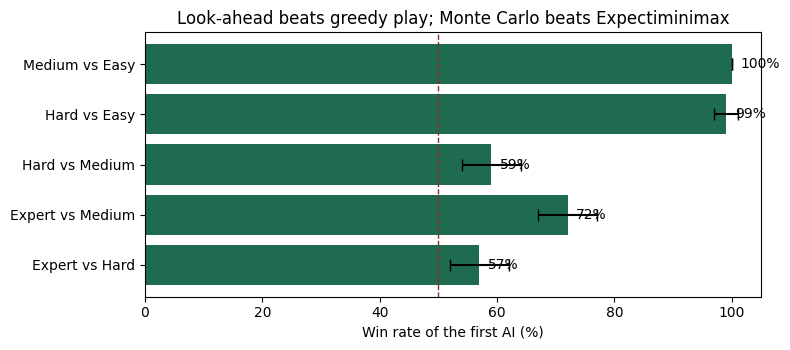

In [16]:
import matplotlib.pyplot as plt
names = ["Medium vs Easy", "Hard vs Easy", "Hard vs Medium", "Expert vs Medium", "Expert vs Hard"]
rates = [100, 99, 59, 72, 57]
errors = [0, 2, 5, 5, 5]
fig, axis = plt.subplots(figsize=(8, 3.6))
bars = axis.barh(names[::-1], rates[::-1], xerr=errors[::-1], color="#1f6b4f", capsize=4)
axis.axvline(50, color="#8a2a2a", linestyle="--", linewidth=1)
axis.set_xlim(0, 105)
axis.set_xlabel("Win rate of the first AI (%)")
axis.set_title("Look-ahead beats greedy play; Monte Carlo beats Expectiminimax")
for bar, r in zip(bars, rates[::-1]):
    axis.text(r + 1.5, bar.get_y() + bar.get_height() / 2, f"{r}%", va="center")
plt.tight_layout()
plt.show()

### 2.8 Automated tests

In [17]:
import unittest

os.environ["NO_COLOR"] = "1"                          # plain text output in the notebook
suite = unittest.defaultTestLoader.discover("tests")
result = unittest.TextTestRunner(verbosity=2, stream=sys.stdout).run(suite)
print("All tests passed" if result.wasSuccessful() else "Some tests failed")

pygame-ce 2.5.8 (SDL 2.32.10, Python 3.14.5)
test_cube_thresholds (test_backgammon_ai.AITests.test_cube_thresholds)
The AI takes a double at 25% or more and offers one only between 70% and 88%. ... 

ok


test_evaluation_of_a_finished_game (test_backgammon_ai.AITests.test_evaluation_of_a_finished_game)
A won game scores +WIN_SCORE for the winner and -WIN_SCORE for the loser. ... 

ok


test_every_ai_returns_a_legal_turn (test_backgammon_ai.AITests.test_every_ai_returns_a_legal_turn)
Easy, Medium, Hard and Expert always choose one of the legal turns they were given. ... 

ok


... (30 outputs left out)

test_single_game (test_backgammon_ai.ScoringTests.test_single_game)
The loser bore off a checker: one point times the cube. ... 

ok


----------------------------------------------------------------------
Ran 19 tests in 3.126s

OK


All tests passed


## Part 3: Play the game
Running this cell opens the game in its own window (it keeps running after the cell finishes).
Controls: **Space** roll, **H** hint, **T** search tree, click the cube or **D** to double,
**B** board set, **M** sound. On the title screen: **1-4** level, **W** watch two AIs,
**U** tutorial.

In [ ]:
import subprocess
import sys

game = subprocess.Popen([sys.executable, "main.py"])   # opens the game window
print("The game is starting in a new window.")